# 01. 데이터 수집

금리 플로어 분석에 필요한 데이터를 모으는 노트북이다.

| 섹션 | 내용 | 상태 |
|---|---|---|
| 1. 금리 데이터 | FRED: SOFR, 연방기금금리, 3개월 국채, 수익률곡선 | 완료 |
| **2. USDC 유통량** | DefiLlama: USDC, USDT 일별 유통량 | 완료 |
| **3. Circle 재무제표** | SEC EDGAR: 고정비 C, 배분율 s | 완료 |

**FRED**: 미국 세인트루이스 연방준비은행이 운영하는 무료 경제 데이터베이스. API 키 없이 CSV 파일로 받을 수 있다.
- **API 키**: 데이터 사이트가 "누가 요청했는지" 확인하려고 발급하는 비밀번호 같은 것. FRED CSV 다운로드에는 필요 없다.
- **CSV**: 쉼표(,)로 칸을 나눈 단순한 표 파일. 엑셀로도 열린다.

# 1. 금리 데이터

**순서**
1. 준비 → 2. 다운로드(원본 저장) → 3. 숫자로 바꾸기·결측치 → 4. 기간·결측치 표 → 5. 영업일 기준 한 표로 합치기
→ 6. SOFR와 DFF 비교 → 7. '기준금리' 열 만들기 → 8. 베이시스(SOFR − 3개월 국채) → 9. 그래프 → 10. 저장 → 11. 발견한 점 요약

## 1-1. 준비

### 라이브러리 불러오기
이 셀이 하는 일: 이번 섹션에서 쓸 도구(**라이브러리**: 다른 사람이 만들어 둔 코드 묶음)를 불러온다.
- `requests`: 인터넷에서 파일을 받는 도구
- `pandas`: 엑셀처럼 표 형태 데이터를 다루는 도구
- `matplotlib`: 그래프를 그리는 도구

In [1]:
import sys
from pathlib import Path   # 폴더·파일 경로를 다루는 도구

import requests
import pandas as pd
import matplotlib.pyplot as plt

### 폴더 경로 정하기
이 셀이 하는 일: 데이터와 그림을 저장할 폴더를 정하고, 없으면 만든다.
- `data/raw/fred/`: FRED에서 받은 **원본 그대로** (절대 수정하지 않는다)
- `data/processed/`: 정리한 데이터
- `output/figures/`: 발제안에 넣을 그림

In [2]:
# 노트북이 notebooks/ 폴더 안에 있으면 한 단계 위가 프로젝트 폴더
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_DIR = PROJECT / "data" / "raw" / "fred"
PROC_DIR = PROJECT / "data" / "processed"
FIG_DIR = PROJECT / "output" / "figures"

for folder in [RAW_DIR, PROC_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)   # 없으면 만들고, 있으면 그냥 넘어감

sys.path.append(str(PROJECT))   # src/ 폴더의 코드를 불러올 수 있게 프로젝트 폴더를 등록
print("프로젝트 폴더:", PROJECT)

프로젝트 폴더: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor


### 그래프 설정 (한글 폰트)
이 셀이 하는 일: 그래프에 한글이 깨지지 않도록 운영체제에 맞는 한글 폰트를 설정한다. (윈도우는 **맑은 고딕**)
- 설정 코드는 다른 노트북에서도 똑같이 쓰므로 `src/plot_style.py`에 함수로 만들어 두고 여기서는 불러서 쓰기만 한다.
- **함수**: 자주 하는 작업을 한 번 정의해 두고 이름으로 불러 쓰는 것.

In [3]:
from src.plot_style import setup_plot_style, COLORS, MUTED, TEXT_SUB, SHADE

font = setup_plot_style()
print("사용 폰트:", font)

사용 폰트: Malgun Gothic


## 1-2. 다운로드 (원본 저장)

### 받을 데이터 목록
이 셀이 하는 일: 받을 시리즈(데이터 하나하나)의 ID, 한국어 설명, 시작일을 적어 둔다.

| 시리즈 | 뜻 | 왜 필요한가 |
|---|---|---|
| **SOFR** | 담보부 익일물 금리. 미국 국채를 담보로 하루 동안 돈을 빌릴 때의 금리 | 플로어를 정산하는 **기준금리**. 2018년 4월부터만 있다 |
| **DFF** | 연방기금 실효금리. 은행끼리 하루 동안 빌려줄 때의 금리 | SOFR가 없는 2018년 이전을 **대신 채우는** 용도 |
| **DTB3** | 3개월 만기 국채(T-bill) 금리 | 준비금이 실제로 많이 들어가는 자산 → 실제 수익률 대용 |
| **DGS1MO ~ DGS10** | 만기 1개월~10년 국채 금리 | 만기별로 늘어놓으면 **수익률곡선** (시장이 예상하는 앞으로의 금리 경로) |

- **익일물(overnight)**: 오늘 빌려 내일 갚는 하루짜리 거래.

In [4]:
START = "2000-01-01"   # SOFR를 뺀 나머지는 2000년부터 받는다

FRED_SERIES = {
    # 시리즈 ID: (설명, 시작일)
    "SOFR":   ("담보부 익일물 금리",        None),    # None = 처음부터 전체
    "DFF":    ("연방기금 실효금리",         START),
    "DTB3":   ("3개월 국채 (할인율 기준)",   START),
    "DGS1MO": ("국채 1개월",               START),
    "DGS3MO": ("국채 3개월",               START),
    "DGS6MO": ("국채 6개월",               START),
    "DGS1":   ("국채 1년",                 START),
    "DGS2":   ("국채 2년",                 START),
    "DGS3":   ("국채 3년",                 START),
    "DGS5":   ("국채 5년",                 START),
    "DGS10":  ("국채 10년",                START),
}
print(f"받을 시리즈: {len(FRED_SERIES)}개")

받을 시리즈: 11개


### 다운로드 함수 만들기
이 셀이 하는 일: "시리즈 ID를 주면 FRED에서 CSV를 받아 `data/raw/fred/`에 **받은 그대로** 저장하는" 함수를 정의한다.
- 주소 끝의 `cosd=2000-01-01`은 "이 날짜부터 달라"는 뜻이다.
- 이미 받은 파일이 있으면 다시 받지 않는다. 최신 데이터로 새로 받고 싶으면 `refresh=True`로 부른다.

In [5]:
def download_fred(series_id, start=None, refresh=False):
    # FRED에서 시리즈 하나를 CSV로 받아 원본 그대로 저장한다
    path = RAW_DIR / f"{series_id}.csv"

    if path.exists() and not refresh:
        print(f"{series_id:7s} 이미 받은 파일이 있어 건너뜀")
        return path

    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    if start:
        url += f"&cosd={start}"

    response = requests.get(url, timeout=60)
    response.raise_for_status()          # 다운로드에 실패하면 여기서 에러를 내고 멈춘다
    path.write_bytes(response.content)   # 받은 내용을 한 글자도 바꾸지 않고 저장
    print(f"{series_id:7s} 저장 완료 → {path.name}")
    return path

### 다운로드 실행
이 셀이 하는 일: 목록에 있는 11개 시리즈를 차례로 받는다. (처음엔 10~30초 걸린다.)

In [6]:
REFRESH = False   # 최신 데이터로 다시 받고 싶으면 True로 바꾸고 실행

for series_id, (desc, start) in FRED_SERIES.items():
    download_fred(series_id, start=start, refresh=REFRESH)

SOFR    이미 받은 파일이 있어 건너뜀


DFF     이미 받은 파일이 있어 건너뜀
DTB3    이미 받은 파일이 있어 건너뜀
DGS1MO  이미 받은 파일이 있어 건너뜀
DGS3MO  이미 받은 파일이 있어 건너뜀
DGS6MO  이미 받은 파일이 있어 건너뜀
DGS1    이미 받은 파일이 있어 건너뜀
DGS2    이미 받은 파일이 있어 건너뜀
DGS3    이미 받은 파일이 있어 건너뜀
DGS5    이미 받은 파일이 있어 건너뜀
DGS10   이미 받은 파일이 있어 건너뜀


## 1-3. 숫자로 바꾸기와 결측치

### 원본 파일 들여다보기
이 셀이 하는 일: 10년물(DGS10) 원본 파일의 첫 줄들과, 값이 비어 있는 줄을 그대로 출력해 본다.
- **결측치**: 값이 있어야 할 자리가 비어 있는 것.
- FRED는 휴일처럼 값이 없는 날을 예전엔 `.`(마침표)로, 지금은 **빈 칸**(`2025-12-25,` 처럼 쉼표 뒤가 비어 있음)으로 표시한다. 우리 파일이 어느 쪽인지 직접 확인해 보자.

In [7]:
lines = (RAW_DIR / "DGS10.csv").read_text().splitlines()

print("--- 처음 3줄 ---")
print("\n".join(lines[:3]))

print("--- 값이 비어 있는 줄 (최근 3개) ---")
empty_lines = [line for line in lines if line.endswith(",") or line.endswith(",.")]
print("\n".join(empty_lines[-3:]))

--- 처음 3줄 ---
observation_date,DGS10
2000-01-03,6.58
2000-01-04,6.49
--- 값이 비어 있는 줄 (최근 3개) ---
2026-07-03,
2026-09-07,
2026-10-12,


### 읽어서 숫자로 바꾸기
이 셀이 하는 일: 원본 CSV를 읽고, 금리 칸을 **숫자**로 바꾼다.
- 파일에서 읽은 값은 처음엔 '글자'일 수 있다. 글자 `"4.12"`는 계산이 안 되므로 숫자 `4.12`로 바꿔야 한다.
- `pd.to_numeric(..., errors="coerce")`: 숫자로 바꾸되, **숫자로 바꿀 수 없는 것(`.`이나 빈 칸)은 `NaN`으로** 바꾸라는 뜻.
- **NaN**(Not a Number): pandas에서 "값 없음"을 나타내는 표시. 평균 같은 계산을 할 때 자동으로 빠진다.

In [8]:
def read_fred(series_id):
    # 원본 CSV를 읽어 '날짜 → 금리(%)' 형태로 돌려준다
    df = pd.read_csv(RAW_DIR / f"{series_id}.csv",
                     dtype=str,            # 일단 전부 글자로 읽고
                     index_col=0)          # 첫 칸(날짜)을 행 이름(인덱스)으로
    df.index = pd.to_datetime(df.index)                         # 날짜 글자 → 날짜
    return pd.to_numeric(df[series_id], errors="coerce")       # 금리 글자 → 숫자 ('.'·빈 칸 → NaN)

raw = {series_id: read_fred(series_id) for series_id in FRED_SERIES}
raw["DGS10"].tail()

observation_date
2026-10-20    5.12
2026-10-21    5.13
2026-10-22    4.96
2026-10-23    5.00
2026-10-26    5.00
Name: DGS10, dtype: float64

### 결측치를 어떻게 처리할까?
이 노트북에서 정한 원칙은 세 가지다.

1. **개별 시리즈는 채우지 않는다.** 비어 있는 날은 `NaN` 그대로 둔다. 없는 값을 지어내면 나중에 변동성 같은 계산이 왜곡될 수 있다.
2. **표를 합칠 때는 영업일(월~금) 기준으로 맞춘다.** DFF는 주말에도 값이 있지만, 금요일 금리를 주말까지 그대로 적용한 것이라 주말 행을 빼도 정보가 사라지지 않는다.
3. **'기준금리' 열만은 빈 칸 없이 만든다.** 시뮬레이션에 쓸 열이라 빈 칸이 있으면 안 된다. 휴일에는 시장이 열리지 않아 새 금리가 정해지지 않으므로, **직전 영업일 값**을 그대로 쓴다. 이렇게 채운 날은 따로 표시해 둔다.

## 1-4. 기간·결측치 확인

### 시리즈별 요약표
이 셀이 하는 일: 시리즈마다 시작일, 종료일, 결측치 개수를 표로 보여준다.
- 결측치는 각 시리즈의 **첫 값 ~ 마지막 값 사이**에서만 센다.

In [9]:
def count_missing(s):
    s = s.loc[s.first_valid_index():s.last_valid_index()]   # 첫 값 ~ 마지막 값 사이만
    return int(s.isna().sum())

summary = pd.DataFrame({
    "설명":         {k: FRED_SERIES[k][0] for k in raw},
    "시작일":       {k: s.first_valid_index().date() for k, s in raw.items()},
    "종료일":       {k: s.last_valid_index().date() for k, s in raw.items()},
    "값 있는 날":    {k: int(s.notna().sum()) for k, s in raw.items()},
    "결측치 개수":   {k: count_missing(s) for k, s in raw.items()},
})
summary["결측 비율(%)"] = (summary["결측치 개수"] / (summary["값 있는 날"] + summary["결측치 개수"]) * 100).round(1)
summary

,설명,시작일,종료일,값 있는 날,결측치 개수,결측 비율(%)
SOFR,담보부 익일물 금리,2018-04-03,2026-10-26,2139,96,4.3
DFF,연방기금 실효금리,2000-01-01,2026-10-26,9796,0,0.0
DTB3,3개월 국채 (할인율 기준),2000-01-03,2026-10-26,6707,289,4.1
DGS1MO,국채 1개월,2001-07-31,2026-10-26,6311,274,4.2
DGS3MO,국채 3개월,2000-01-03,2026-10-26,6707,289,4.1
DGS6MO,국채 6개월,2000-01-03,2026-10-26,6707,289,4.1
DGS1,국채 1년,2000-01-03,2026-10-26,6707,289,4.1
DGS2,국채 2년,2000-01-03,2026-10-26,6707,289,4.1
DGS3,국채 3년,2000-01-03,2026-10-26,6707,289,4.1
DGS5,국채 5년,2000-01-03,2026-10-26,6707,289,4.1


### 결측치가 정말 휴일인지 확인
이 셀이 하는 일: 10년물(DGS10)과 SOFR의 최근 결측 날짜를 요일과 함께 뽑아 본다.
- 1월 1일, 독립기념일(7월 4일), 추수감사절(11월 넷째 목요일), 크리스마스 같은 미국 공휴일이 나오면 정상이다.
- 공휴일이 아닌 **성금요일**(부활절 직전 금요일)도 나올 수 있다. 미국 채권시장이 쉬는 날이라 SOFR가 공표되지 않는다.
- DFF는 결측치가 0개다. 휴일에도 직전 값을 그대로 적어 두기 때문이다.

In [10]:
for series_id in ["DGS10", "SOFR"]:
    s = raw[series_id]
    print(series_id, s[s.isna()].index[-8:].strftime("%Y-%m-%d(%a)").tolist())

DGS10 ['2026-01-01(Thu)', '2026-01-19(Mon)', '2026-02-16(Mon)', '2026-05-25(Mon)', '2026-06-19(Fri)', '2026-07-03(Fri)', '2026-09-07(Mon)', '2026-10-12(Mon)']
SOFR ['2026-01-19(Mon)', '2026-02-16(Mon)', '2026-04-03(Fri)', '2026-05-25(Mon)', '2026-06-19(Fri)', '2026-07-03(Fri)', '2026-09-07(Mon)', '2026-10-12(Mon)']


## 1-5. 영업일 기준 한 표로 합치기
이 셀이 하는 일: 2000년 1월 3일(첫 영업일)부터 가장 최근 날짜까지 **영업일(월~금) 달력**을 만들고, 11개 시리즈를 그 달력에 맞춰 한 표(`rates`)로 붙인다.
- 2018년 4월 전에는 SOFR가 없으므로 그 칸은 `NaN`이다. (다음 단계에서 DFF로 채운다)

In [11]:
last_date = max(s.last_valid_index() for s in raw.values())
bdays = pd.bdate_range("2000-01-01", last_date)   # 월~금 날짜 목록

rates = pd.DataFrame({k: s.reindex(bdays) for k, s in raw.items()})   # 달력에 맞춰 줄 세우기
rates.index.name = "date"

print("표 크기 (행, 열):", rates.shape)
rates.tail()

표 크기 (행, 열): (6996, 11)


,SOFR,DFF,DTB3,DGS1MO,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS10
date,,,,,,,,,,,
2026-10-20,3.88,3.88,4.08,4.10,4.26,4.36,4.51,4.79,4.86,4.94,5.12
2026-10-21,3.88,3.88,4.07,4.09,4.25,4.35,4.52,4.81,4.89,4.95,5.13
2026-10-22,3.90,3.88,4.04,4.11,4.22,4.29,4.41,4.65,4.72,4.78,4.96
2026-10-23,3.92,3.88,4.04,4.11,4.22,4.30,4.44,4.69,4.75,4.82,5.00
2026-10-26,3.93,3.88,4.05,4.11,4.22,4.35,4.47,4.68,4.79,4.84,5.00


## 1-6. SOFR와 DFF는 얼마나 비슷한가? (이어 붙이기 전 확인)

2018년 이전을 DFF로 채우려면, 두 금리가 겹치는 기간(2018-04~)에 **거의 같게 움직였는지** 먼저 확인해야 한다. 차이가 크다면 DFF에 차이만큼 더하거나 빼서 맞춰야 한다.

### 차이 통계
이 셀이 하는 일: 두 값이 모두 있는 날만 골라 차이(SOFR − DFF)를 **bp** 단위로 계산하고 요약한다.
- **bp(베이시스 포인트)**: 0.01%p. 예: 3.00% → 3.25%는 25bp 상승.
- **중앙값**: 크기순으로 줄 세웠을 때 한가운데 값. 2019년 9월처럼 한 번 크게 튄 값에 덜 흔들린다.
- **표준편차**: 값들이 평균에서 보통 얼마나 떨어져 있는지.

In [12]:
overlap = rates[["SOFR", "DFF"]].dropna()            # 둘 다 값이 있는 날만
diff_bp = (overlap["SOFR"] - overlap["DFF"]) * 100   # %p → bp

pd.Series({
    "비교한 날 수":     len(diff_bp),
    "평균(bp)":        diff_bp.mean(),
    "중앙값(bp)":       diff_bp.median(),
    "표준편차(bp)":     diff_bp.std(),
    "하위 5%(bp)":      diff_bp.quantile(0.05),
    "상위 5%(bp)":      diff_bp.quantile(0.95),
    "최대(bp)":        diff_bp.max(),
    "최대인 날":        diff_bp.idxmax().date(),
}).to_frame("SOFR − DFF")

,SOFR − DFF
비교한 날 수,2139
평균(bp),-0.201964
중앙값(bp),-1.0
표준편차(bp),8.182688
하위 5%(bp),-6.0
상위 5%(bp),7.0
최대(bp),295.0
최대인 날,2019-09-17


### 차이 그래프
이 셀이 하는 일: 날짜별 차이(SOFR − DFF)를 그린다. 점선은 평균이다.
- 2019년 9월 17일 한 번 크게 튄 값 때문에 그래프가 납작해지지 않도록, 세로축을 ±40bp로 잘라서 그리고 잘린 값은 글씨로 적었다.

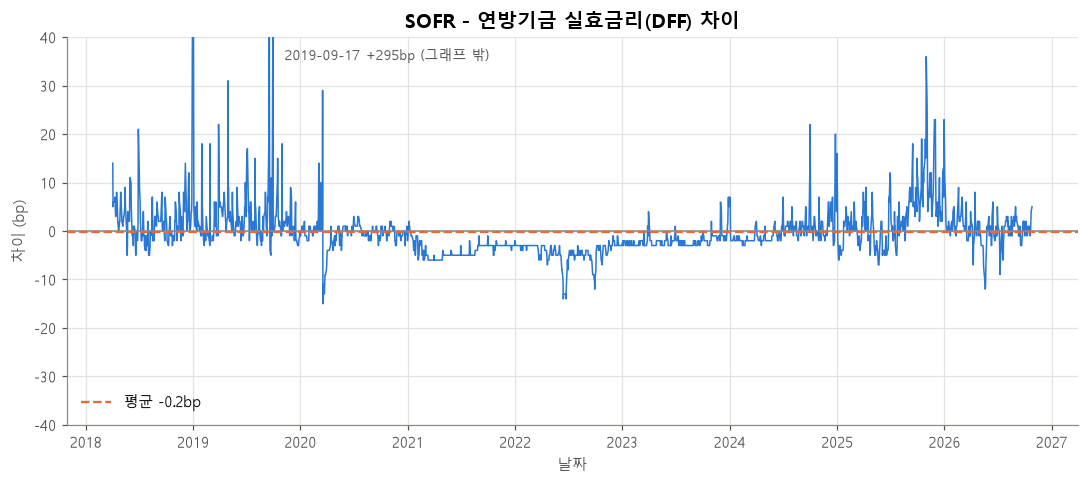

In [13]:
fig, ax = plt.subplots()
ax.plot(diff_bp.index, diff_bp.values, color=COLORS[0], linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axhline(diff_bp.mean(), color=COLORS[1], linestyle="--", linewidth=1.5,
           label=f"평균 {diff_bp.mean():.1f}bp")

ax.set_ylim(-40, 40)
spike_day = diff_bp.idxmax()
ax.annotate(f"{spike_day:%Y-%m-%d} +{diff_bp.max():.0f}bp (그래프 밖)",
            xy=(spike_day, 40), xytext=(10, -15), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)

ax.set_title("SOFR - 연방기금 실효금리(DFF) 차이")
ax.set_xlabel("날짜")
ax.set_ylabel("차이 (bp)")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_sofr_minus_dff.png", dpi=200)
plt.show()

**해석**
- 평균 차이는 거의 0bp이고, 90%의 날이 약 ±7bp 안에 있다. 금리 수준(0~5%)에 비하면 아주 작다.
- 튀는 날은 주로 **월말·분기말**과 2019년 9월 단기자금시장 경색 때다. SOFR는 담보 거래라 국채 수급 영향을 더 받는다.
- 2021~22년에는 SOFR가 DFF보다 4~5bp 낮게, 2019·2025년에는 몇 bp 높게 유지된 시기가 있다. 시장에 돈이 많을 때는 SOFR가 더 낮아지는 경향이 있다.
- **결론: 차이를 보정하지 않고 DFF를 그대로 이어 붙인다.** 다만 2018년 이전의 DFF는 SOFR보다 **월말 출렁임이 작아** 변동성을 조금 덜 보여줄 수 있다는 점은 기억해 두자.

## 1-7. '기준금리' 열 만들기

### SOFR + DFF 이어 붙이기
이 셀이 하는 일: 아래 규칙으로 `base_rate`(기준금리) 열과, 그 값이 어디서 왔는지 적는 `base_source`(출처) 열을 만든다.

| 구간 | base_rate 값 | base_source |
|---|---|---|
| SOFR 시작일(2018-04-03) 이전 | DFF | `DFF 대체` |
| 그 이후 | SOFR | `SOFR` |
| 그 이후 중 SOFR 휴일 | 직전 영업일 SOFR | `휴일(직전값)` |

In [14]:
sofr_start = raw["SOFR"].first_valid_index()
before_sofr = rates.index < sofr_start                 # SOFR 시작 전이면 True

base_rate = rates["SOFR"].copy()
base_source = pd.Series("SOFR", index=rates.index)

base_rate[before_sofr] = rates.loc[before_sofr, "DFF"]   # 시작 전 구간은 DFF로
base_source[before_sofr] = "DFF 대체"

holiday = base_rate.isna()                    # 그래도 비어 있는 날 = SOFR 휴일
base_rate = base_rate.ffill()                 # ffill: 바로 위(직전 날짜) 값으로 채우기
base_source[holiday] = "휴일(직전값)"

rates["base_rate"] = base_rate
rates["base_source"] = base_source

print("SOFR 시작일:", sofr_start.date())
print("base_rate 빈 칸 수:", rates["base_rate"].isna().sum())
rates["base_source"].value_counts()

SOFR 시작일: 2018-04-03
base_rate 빈 칸 수: 0


base_source
DFF 대체     4761
SOFR       2139
휴일(직전값)      96
Name: count, dtype: int64

이 셀이 하는 일: SOFR 시작일 앞뒤 며칠을 보여줘서 DFF → SOFR로 자연스럽게 넘어가는지 확인한다.

In [15]:
rates.loc["2018-03-28":"2018-04-06", ["DFF", "SOFR", "base_rate", "base_source"]]

,DFF,SOFR,base_rate,base_source
date,,,,
2018-03-28,1.68,NaN,1.68,DFF 대체
2018-03-29,1.68,NaN,1.68,DFF 대체
2018-03-30,1.67,NaN,1.67,DFF 대체
2018-04-02,1.68,NaN,1.68,DFF 대체
2018-04-03,1.69,1.83,1.83,SOFR
2018-04-04,1.69,1.74,1.74,SOFR
2018-04-05,1.69,1.75,1.75,SOFR
2018-04-06,1.69,1.75,1.75,SOFR


## 1-8. 베이시스: SOFR − 3개월 국채

플로어는 **SOFR**로 정산되지만, 발행사가 실제로 버는 건 준비금에 담긴 **국채 수익률**이다. 둘이 따로 움직이면 헤지가 딱 맞지 않는데, 이를 **베이시스 위험**이라고 한다.

### 먼저 단위 맞추기: 할인율 → 수익률
DTB3는 **할인율**(discount rate)로 표시된다. SOFR와 단위가 달라서 그대로 빼면 안 된다.

- **할인율**: 이자를 **만기에 받을 돈(액면 100)** 으로 나눈 값. 예) 99에 사서 100 받으면 1 ÷ 100
- **수익률**(SOFR와 같은 방식): 이자를 **지금 낸 돈(99)** 으로 나눈 값. 1 ÷ 99
- 같은 거래라도 수익률이 할인율보다 조금 크다. 그래서 DTB3를 SOFR 방식으로 바꿔 준다.

$$\text{수익률} = \frac{360 \times d}{360 - 91 \times d}$$

($d$: 할인율(소수), 91: 3개월 국채의 만기 일수, 360: 미국 단기금리의 1년 일수 관행)
- 직관: 분모가 360보다 조금 작아서 할인율보다 살짝 커진다. 금리가 4%면 약 4bp 차이.

이 셀이 하는 일: DTB3를 수익률로 바꾼 `DTB3_MM` 열을 만들고, 바꾸기 전후 차이를 확인한다.

In [16]:
d = rates["DTB3"] / 100                                       # % → 소수 (4.0% → 0.04)
rates["DTB3_MM"] = 360 * d / (360 - 91 * d) * 100             # 다시 % 단위로

conv_gap_bp = (rates["DTB3_MM"] - rates["DTB3"]) * 100
print(f"할인율 → 수익률 변환으로 늘어난 폭: 최근 {conv_gap_bp.dropna().iloc[-1]:.1f}bp, 최대 {conv_gap_bp.max():.1f}bp")
rates[["DTB3", "DTB3_MM"]].dropna().tail()

할인율 → 수익률 변환으로 늘어난 폭: 최근 4.2bp, 최대 10.0bp


,DTB3,DTB3_MM
date,,
2026-10-20,4.08,4.122517
2026-10-21,4.07,4.112308
2026-10-22,4.04,4.081683
2026-10-23,4.04,4.081683
2026-10-26,4.05,4.091891


### 베이시스 그래프
이 셀이 하는 일: SOFR와 DTB3(수익률 환산)가 모두 있는 날만 골라 차이(bp)를 그리고, 연도별 평균을 표로 보여준다.
- 세로축은 ±130bp로 잘랐다. 2019년 9월 17일 값은 글씨로 적었다.

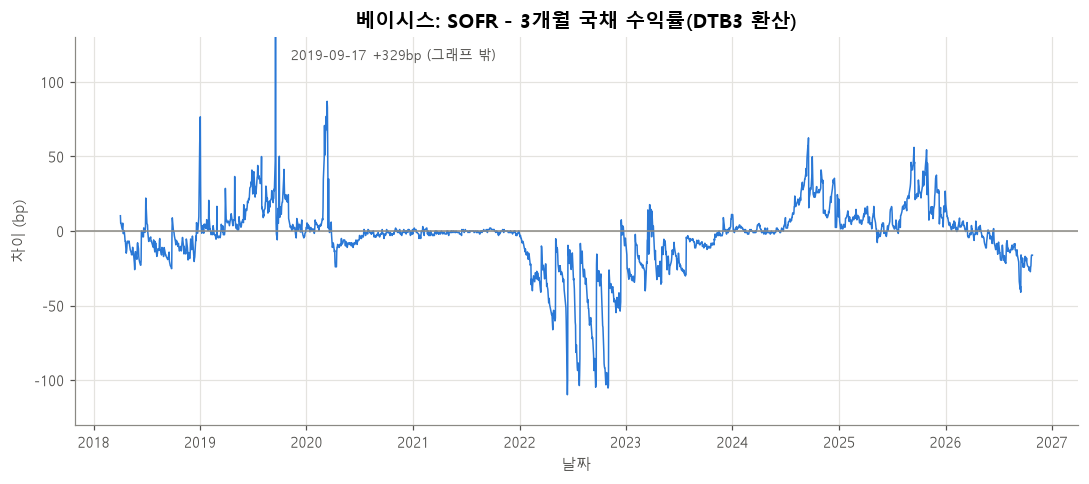

전체: 평균 -3.3bp, 표준편차 22.9bp


date,2018,2019,2020,2021,2022,2023,2024,2025,2026
연평균 베이시스(bp),-9.1,13.0,0.4,-0.6,-40.5,-13.1,11.5,13.6,-7.2


In [17]:
both = rates[["SOFR", "DTB3_MM"]].dropna()
basis_bp = (both["SOFR"] - both["DTB3_MM"]) * 100

fig, ax = plt.subplots()
ax.plot(basis_bp.index, basis_bp.values, color=COLORS[0], linewidth=1)
ax.axhline(0, color=MUTED, linewidth=1)

ax.set_ylim(-130, 130)
spike_day = basis_bp.idxmax()
ax.annotate(f"{spike_day:%Y-%m-%d} +{basis_bp.max():.0f}bp (그래프 밖)",
            xy=(spike_day, 130), xytext=(10, -15), textcoords="offset points",
            color=TEXT_SUB, fontsize=9)

ax.set_title("베이시스: SOFR - 3개월 국채 수익률(DTB3 환산)")
ax.set_xlabel("날짜")
ax.set_ylabel("차이 (bp)")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_sofr_minus_tbill.png", dpi=200)
plt.show()

print(f"전체: 평균 {basis_bp.mean():.1f}bp, 표준편차 {basis_bp.std():.1f}bp")
basis_bp.groupby(basis_bp.index.year).mean().round(1).to_frame("연평균 베이시스(bp)").T

**이 차이가 의미하는 것** — 단위를 맞춘 뒤에도 남는 차이는 세 가지가 섞여 있다.

1. **만기 차이 → 금리 예상** (가장 크다)
   SOFR는 하루짜리, 3개월 국채는 3개월짜리라서, 앞으로 3개월 동안의 금리 예상이 국채에 먼저 반영된다.
   - 시장이 **인상**을 예상할 때(2022년) → 국채가 먼저 올라 차이가 **음(−)** (2022년 평균 약 −40bp)
   - 시장이 **인하**를 예상할 때(2019년, 2024~25년) → 국채가 먼저 내려 차이가 **양(+)**
2. **담보·수급 차이**: 월말·분기말이나 2019년 9월처럼 단기자금이 부족할 때 SOFR만 튄다. 하루 이틀 만에 돌아온다.
3. **국채 수급**: 국채 발행이 많거나 적을 때 국채 금리만 따로 움직인다.

**우리 연구에 주는 의미**
- 발행사가 SOFR 플로어를 사면, 정산은 SOFR로 받는데 수익은 국채로 번다. 금리 **인하가 예상되는** 시기에는 국채 수익이 SOFR보다 **먼저** 떨어지므로, 플로어 보상이 손실보다 늦게 들어올 수 있다.
- 장기 평균은 0bp 근처라 큰 방향성은 없지만, 표준편차가 20bp 넘게 출렁인다. 10단계(한계 점검)의 베이시스 위험 근거로 쓴다.

## 1-9. 그래프

### 기준금리 추이 (2000년~현재)
이 셀이 하는 일: `base_rate`를 2000년부터 그린다.
- 선 색: **주황 = DFF 대체 구간**, **파랑 = SOFR 구간**
- 회색 음영: 연준의 **금리 인하 사이클** (첫 인하 ~ 마지막 인하, 연준 발표일 기준)
- 빗금: **제로금리** 구간 (기준금리 0.25% 미만)

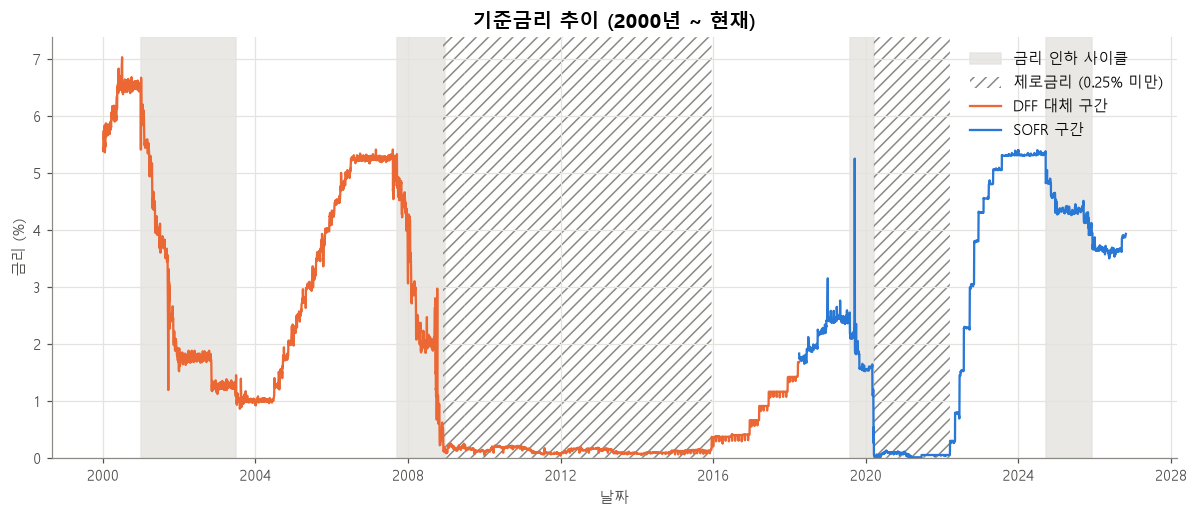

In [18]:
# 연준 금리 인하 사이클 (첫 인하일, 마지막 인하일)
CUT_CYCLES = [
    ("2001-01-03", "2003-06-25"),   # 닷컴 버블 붕괴
    ("2007-09-18", "2008-12-16"),   # 글로벌 금융위기
    ("2019-07-31", "2020-03-15"),   # 보험성 인하 → 코로나
    ("2024-09-18", "2025-12-10"),   # 인플레이션 진정 후 인하
]

base = rates["base_rate"]
is_dff = rates["base_source"] == "DFF 대체"

fig, ax = plt.subplots(figsize=(11, 4.8))

for i, (start, end) in enumerate(CUT_CYCLES):
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SHADE, alpha=0.8,
               label="금리 인하 사이클" if i == 0 else None)

ax.fill_between(base.index, 0, base.max() * 1.05, where=base < 0.25,
                facecolor="none", edgecolor=MUTED, hatch="///", linewidth=0,
                label="제로금리 (0.25% 미만)")

ax.plot(base[is_dff].index, base[is_dff].values, color=COLORS[1], label="DFF 대체 구간")
ax.plot(base[~is_dff].index, base[~is_dff].values, color=COLORS[0], label="SOFR 구간")

ax.set_ylim(0, base.max() * 1.05)
ax.set_title("기준금리 추이 (2000년 ~ 현재)")
ax.set_xlabel("날짜")
ax.set_ylabel("금리 (%)")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_base_rate_2000.png", dpi=200)
plt.show()

**읽는 법**
- 2000년 이후 인하 사이클은 4번이고, 그중 두 번(2008년, 2020년)은 **제로금리**까지 내려갔다. 제로금리 기간을 합치면 약 9년이다.
- 발행사 입장에서 제로금리는 준비금 수익이 사실상 0이 되는 **최악의 시나리오**다. 플로어가 막아야 하는 상황이 바로 이것이다.
- 인하는 한번 시작하면 1~2년 동안 수백 bp가 빠르게 내려가지만, 인상은 천천히 올라간다. 금리 모형이 이 비대칭을 얼마나 잡는지 2단계에서 확인해야 한다.

### 최신 수익률곡선
이 셀이 하는 일: 8개 만기 금리가 모두 있는 가장 최근 날짜의 수익률곡선을 그린다.
- 오른쪽으로 **올라가면**(장기 > 단기) 정상 모양, **내려가면** 역전(시장이 앞으로 금리 인하를 예상)이다.
- 가로축 간격은 실제 기간 비율이 아니라 보기 편하게 같은 간격으로 놓았다.

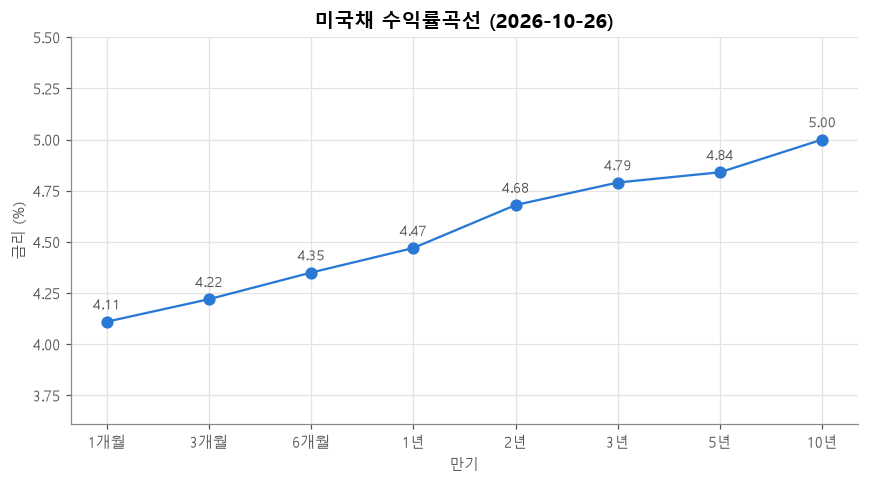

10년 - 3개월 = 78bp, 2년 - 3개월 = 46bp


In [19]:
curve_ids = ["DGS1MO", "DGS3MO", "DGS6MO", "DGS1", "DGS2", "DGS3", "DGS5", "DGS10"]
curve_labels = ["1개월", "3개월", "6개월", "1년", "2년", "3년", "5년", "10년"]

latest = rates[curve_ids].dropna().iloc[-1]   # 8개가 모두 있는 마지막 날

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve_labels, latest.values, color=COLORS[0], marker="o", markersize=7)
for x, y in zip(curve_labels, latest.values):
    ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=9, color=TEXT_SUB)

ax.set_ylim(latest.min() - 0.5, latest.max() + 0.5)
ax.set_title(f"미국채 수익률곡선 ({latest.name:%Y-%m-%d})")
ax.set_xlabel("만기")
ax.set_ylabel("금리 (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "1_yield_curve_latest.png", dpi=200)
plt.show()

print(f"10년 - 3개월 = {(latest['DGS10'] - latest['DGS3MO']) * 100:.0f}bp, "
      f"2년 - 3개월 = {(latest['DGS2'] - latest['DGS3MO']) * 100:.0f}bp")

## 1-10. 저장
이 셀이 하는 일: 정리한 표를 `data/processed/rates.parquet`로 저장하고, 다시 읽어서 제대로 저장됐는지 확인한다.
- **parquet**: CSV보다 빠르고 작은 표 저장 형식. 날짜·숫자 형식이 그대로 유지돼서 다시 읽을 때 변환할 필요가 없다.

| 열 | 내용 |
|---|---|
| `SOFR`, `DFF`, `DTB3`, `DGS1MO` ~ `DGS10` | 원본 값 (결측은 NaN 그대로) |
| `DTB3_MM` | DTB3를 SOFR와 같은 수익률 방식으로 바꾼 값 |
| `base_rate` | 기준금리 (빈 칸 없음) |
| `base_source` | 기준금리 출처: `SOFR` / `DFF 대체` / `휴일(직전값)` |

In [20]:
out_path = PROC_DIR / "rates.parquet"
rates.to_parquet(out_path)

check = pd.read_parquet(out_path)
print("저장 완료:", out_path)
print("행, 열:", check.shape, "| 기간:", check.index[0].date(), "~", check.index[-1].date())
check.dtypes

저장 완료: C:\Users\haley\OneDrive\바탕 화면\stablecoin-floor\data\processed\rates.parquet
행, 열: (6996, 14) | 기간: 2000-01-03 ~ 2026-10-26


SOFR           float64
DFF            float64
DTB3           float64
DGS1MO         float64
DGS3MO         float64
DGS6MO         float64
DGS1           float64
DGS2           float64
DGS3           float64
DGS5           float64
DGS10          float64
base_rate      float64
base_source        str
DTB3_MM        float64
dtype: object

## 1-11. 발견한 점 요약 (2026-10-26 데이터 기준)

**데이터 상태**
- 11개 시리즈 모두 정상으로 받았다. SOFR는 2018-04-03~2026-10-26, 나머지는 2000년~2026-10-26 (2026-10-28에 다시 받음). 국채·DFF는 SOFR보다 공표가 늦어 받는 시점에 따라 하루 정도 뒤처질 수 있다.
- 결측치는 시리즈마다 약 4%이고, 모두 **채권시장 휴장일**(미국 공휴일, 성금요일 등)이다. 데이터 오류는 아니다.
- DGS1MO(1개월물)는 2001-07-31부터만 있다. 수익률곡선 전체(8개 만기)를 쓰는 분석은 2001년 8월부터 가능하다.
- 현재 FRED 파일은 결측을 `.`이 아니라 **빈 칸**으로 표시한다. 두 경우 모두 `NaN`으로 처리되게 해 두었다.

**이상값**
- **2019-09-17 SOFR 급등** (하루 +282bp, 5.25%): 단기자금시장 경색이라는 실제 사건이다. 지우지 않고 남겨 두지만, 금리 모형의 변동성을 추정할 때 이 하루가 결과를 크게 흔들 수 있다. 2단계에서 포함/제외를 비교해야 한다.
- 월말·분기말에 SOFR가 몇~수십 bp 튀는 패턴이 반복된다.

**주의할 점**
- **SOFR ≈ DFF**: 겹치는 기간 평균 차이 약 0bp, 90%가 ±7bp 안 → 보정 없이 이어 붙였다. 단, 2018년 이전 구간(DFF)은 SOFR보다 월말 출렁임이 작다.
- **DTB3는 할인율**이라 수익률보다 최대 10bp 정도 낮게 나온다. 비교할 때는 `DTB3_MM`(환산값)을 쓴다.
- **베이시스**(SOFR − 국채): 평균은 0 근처지만 표준편차가 20bp가 넘고, 금리 예상 방향에 따라 수십 bp씩 한쪽으로 쏠린다(2022년 평균 약 −40bp). 플로어 정산(SOFR)과 실제 수익(국채)이 어긋나는 위험이다.
- **최근 금리 방향 전환**: 2024-09~2025-12 인하 사이클 이후, 데이터상 **2026-09-17에 +25bp 인상**이 있었다. 시뮬레이션 시작점(최신 날짜)의 금리 수준과 수익률곡선 모양이 결과에 직접 영향을 주므로, 2단계에서 최신 곡선을 기준으로 삼아야 한다.
- 2000년 이후 제로금리 기간이 약 9년이다. 모형 추정 기간(2000년~ 또는 2008년~)에 따라 "금리가 0 근처에 머물 확률"이 크게 달라질 수 있다.

# 2. USDC 유통량과 통제 변수

**순서**
1. API 구조 확인 → 2. 다운로드(원본 저장) → 3. 읽어서 표로 바꾸기 → 4. 기간·결측치 → 5. 급격한 변화 확인
→ 6. 이벤트 열 3개 → 7. 통제 변수: 비트코인 가격 → 8. 금리와 합치기 → 9. USDC = 시장 × 점유율 분해
→ 10. 주간·월간 → 11. 그래프 → 12. 저장 → 13. 국면별 정리

**DefiLlama**: 블록체인 위의 자산 규모를 모아서 무료로 공개하는 사이트. 스테이블코인별로 각 블록체인에 얼마나 발행돼 있는지 매일 집계한다.
- **유통량**(circulating supply): 지금 시장에 풀려 있는 코인 개수. USDC 1개 = 1달러 준비금이므로, **유통량 ≈ 준비금 규모 R** 이다.

## 2-1. API 구조 확인

**API**: 프로그램이 다른 서비스에 데이터를 요청하는 창구. 정해진 주소로 요청하면 데이터를 **JSON**으로 돌려준다.
- **JSON**: `{"이름": 값}` 모양으로 데이터를 담는 글자 형식. 파이썬의 딕셔너리(`{}`)·리스트(`[]`)와 거의 같다.

DefiLlama 스테이블코인 API에서 쓸 만한 주소는 이렇다. (API 키 필요 없음)

| 주소 | 돌려주는 것 | 이번에 쓰나 |
|---|---|---|
| `https://stablecoins.llama.fi/stablecoins` | 모든 스테이블코인 목록과 **ID**, 현재 유통량 | ID 확인용 |
| `https://stablecoins.llama.fi/stablecoincharts/all?stablecoin=<ID>` | 그 코인의 **일별 유통량** (모든 체인 합계) | **사용** (USDC, USDT, UST) |
| `https://stablecoins.llama.fi/stablecoincharts/all` (ID 없이) | **모든 스테이블코인 합계**의 일별 유통량 | **사용** (전체 시장) |
| `https://stablecoins.llama.fi/stablecoin/<ID>` | 체인(이더리움, 솔라나 등)별 상세 이력 | 사용 안 함 (너무 상세함) |

### 코인 목록에서 ID 확인
이 셀이 하는 일: 스테이블코인 목록을 받아 USDT, USDC, 그리고 2022년에 붕괴한 테라 UST(지금 이름 USTC)의 ID를 확인한다.

In [21]:
import json   # JSON 글자 ↔ 파이썬 데이터 변환 도구

LLAMA = "https://stablecoins.llama.fi"

coin_list = requests.get(f"{LLAMA}/stablecoins", timeout=60).json()
print("최상위 키:", list(coin_list.keys()))

for coin in coin_list["peggedAssets"]:
    if coin["symbol"] in ["USDT", "USDC", "USTC"]:
        now = coin["circulating"].get("peggedUSD", 0) / 1e9
        print(f"{coin['symbol']}: ID={coin['id']}, 이름={coin['name']}, 현재 유통량={now:,.1f}bn 달러")

최상위 키: ['peggedAssets', 'chains']
USDT: ID=1, 이름=Tether, 현재 유통량=180.3bn 달러
USDC: ID=2, 이름=USD Coin, 현재 유통량=71.5bn 달러
USTC: ID=3, 이름=TerraClassicUSD, 현재 유통량=0.0bn 달러


### 일별 데이터의 모양 확인
이 셀이 하는 일: USDC(ID=2)의 일별 데이터를 받아서, 맨 처음과 맨 마지막 항목을 그대로 출력해 본다.

In [22]:
sample = requests.get(f"{LLAMA}/stablecoincharts/all?stablecoin=2", timeout=60).json()

print("자료형:", type(sample).__name__, "| 항목 수:", len(sample))
print("--- 첫 항목 ---")
print(json.dumps(sample[0], indent=1))
print("--- 마지막 항목 ---")
print(json.dumps(sample[-1], indent=1))

자료형: list | 항목 수: 2972
--- 첫 항목 ---
{
 "date": "1536624000",
 "totalCirculating": {
  "peggedUSD": 2
 },
 "totalCirculatingUSD": {
  "peggedUSD": 2
 }
}
--- 마지막 항목 ---
{
 "date": "1793318400",
 "totalCirculating": {
  "peggedUSD": 71479873890.58
 },
 "totalUnreleased": {
  "peggedUSD": 1105247809.46
 },
 "totalCirculatingUSD": {
  "peggedUSD": 71441245833.01
 },
 "totalMintedUSD": {
  "peggedUSD": 0
 },
 "totalBridgedToUSD": {
  "peggedUSD": 0
 }
}


**응답 구조**: 하루에 항목 하나씩 들어 있는 **리스트**다. 각 항목의 필드(칸)는 이렇다.

| 필드 | 뜻 | 사용 |
|---|---|---|
| `date` | 날짜. **유닉스 시간**(1970-01-01부터 흐른 초)으로 적혀 있다. 예: `1793059200` → 2026-10-26 | **사용** (날짜로 변환) |
| `totalCirculating.peggedUSD` | 유통 중인 **코인 개수** (1개 = 1달러로 계산) | **사용** |
| `totalCirculatingUSD.peggedUSD` | 코인 개수 × **그날 시장 가격** | 비교용으로만 |
| `totalUnreleased` | 발행은 됐지만 아직 시장에 안 풀린 물량 | 사용 안 함 |
| `totalMintedUSD`, `totalBridgedToUSD` | 체인 간 이동 집계용 값 | 사용 안 함 |

- 전체 합계(ID 없이)에는 `peggedEUR`, `peggedJPY`처럼 다른 통화에 고정된 코인도 따로 들어 있다. 우리는 **달러 스테이블코인**(`peggedUSD`)만 쓴다.

**왜 `totalCirculating`(개수)을 쓰나?** 발행사가 준비금을 쥐고 이자를 버는 기준은 **코인 개수**다. 시장 가격이 잠깐 0.88달러로 떨어져도(디페깅) 발행사가 돌려줘야 할 돈은 개수 × 1달러다.
- **디페깅**(de-peg): 1달러에 고정돼야 할 코인 가격이 1달러에서 벗어나는 것.

## 2-2. 다운로드 (원본 저장)

### 다운로드 함수
이 셀이 하는 일: 이름을 주면 일별 데이터를 받아 `data/raw/defillama/<이름>.json`에 **받은 그대로** 저장하는 함수를 만든다.
- `ALL`은 ID 없이 받는 **전체 스테이블코인 합계**다.
- `USTC`(테라 UST)는 전체 합계에서 빼 주려고 받는다. 이유는 2-4에서 설명한다.
- 원본은 기간을 자르지 않고 전체를 저장한다.

In [23]:
LLAMA_DIR = PROJECT / "data" / "raw" / "defillama"
LLAMA_DIR.mkdir(parents=True, exist_ok=True)

STABLECOINS = {"USDC": 2, "USDT": 1, "USTC": 3, "ALL": None}   # 이름: DefiLlama ID (None = 전체 합계)


def download_llama(name, refresh=False):
    # DefiLlama에서 일별 유통량을 받아 원본 그대로 저장한다
    path = LLAMA_DIR / f"{name}.json"

    if path.exists() and not refresh:
        print(f"{name}: 이미 받은 파일이 있어 건너뜀")
        return path

    url = f"{LLAMA}/stablecoincharts/all"
    if STABLECOINS[name] is not None:
        url += f"?stablecoin={STABLECOINS[name]}"

    response = requests.get(url, timeout=60)
    response.raise_for_status()
    path.write_bytes(response.content)   # 받은 내용을 그대로 저장
    print(f"{name}: 저장 완료 → {path.name}")
    return path

### 다운로드 실행
이 셀이 하는 일: USDC, USDT, USTC, 전체 합계를 받는다.

In [24]:
REFRESH_LLAMA = False   # 최신 데이터로 다시 받고 싶으면 True

for name in STABLECOINS:
    download_llama(name, refresh=REFRESH_LLAMA)

USDC: 이미 받은 파일이 있어 건너뜀
USDT: 이미 받은 파일이 있어 건너뜀
USTC: 이미 받은 파일이 있어 건너뜀
ALL: 이미 받은 파일이 있어 건너뜀


## 2-3. 읽어서 표로 바꾸기

### 읽기 함수
이 셀이 하는 일: 저장한 JSON을 읽어서 `날짜 | 유통량(개수) | 시장가치` 표로 바꾸는 함수를 만든다.
- 유닉스 시간 → 날짜로 바꾼다. (`unit="s"`: 초 단위라는 뜻)
- 단위를 **bn(10억) 달러**로 바꾼다. 710억 달러 → `71.0`
- 2020-01-01 이후만 남긴다. (CLAUDE.md 기준: 2018~19년은 규모가 작아 제외)
- **파일을 받은 날의 행은 뺀다.** 그날이 끝나기 전에 집계된 값이라 나중에 바뀔 수 있다. ("오늘"을 기준으로 하면 다음 날 다시 실행할 때 덜 집계된 행이 들어오므로, 파일이 저장된 날짜를 기준으로 한다)

In [25]:
USDC_START = "2020-01-01"


def read_llama(name):
    path = LLAMA_DIR / f"{name}.json"
    items = json.loads(path.read_text())
    df = pd.DataFrame({
        "date":   [int(x["date"]) for x in items],
        "supply": [x.get("totalCirculating", {}).get("peggedUSD") for x in items],
        "value":  [x.get("totalCirculatingUSD", {}).get("peggedUSD") for x in items],
    })
    df["date"] = pd.to_datetime(df["date"], unit="s")    # 유닉스 시간 → 날짜
    df = df.set_index("date")
    df = df / 1e9                                         # 달러 → bn 달러

    downloaded = pd.Timestamp(path.stat().st_mtime, unit="s").normalize()   # 파일을 받은 날 (UTC)
    return df.loc[USDC_START:].loc[lambda x: x.index < downloaded]          # 2020년~, 받은 날 제외

이 셀이 하는 일: 네 개를 모두 읽어 `coins`라는 묶음에 넣고, USDC의 마지막 5일을 보여준다.

In [26]:
coins = {name: read_llama(name) for name in STABLECOINS}
coins["USDC"].tail()

,supply,value
date,,
2026-10-22,72.659635,72.623894
2026-10-23,72.252448,72.233349
2026-10-24,71.858865,71.829216
2026-10-25,71.773113,71.746839
2026-10-26,71.711957,71.663114


### 왜 '개수'를 쓰는지 데이터로 확인
이 셀이 하는 일: SVB 사태 때(2023년 3월) USDC의 **개수**(supply)와 **시장가치**(value)를 나란히 보여준다.
- 3월 11~13일에는 가격이 1달러 아래로 떨어져서 시장가치가 개수보다 더 작다. 하지만 발행사의 준비금은 개수를 따라간다.

In [27]:
svb = coins["USDC"].loc["2023-03-08":"2023-03-15"].copy()
svb["가치 - 개수(bn)"] = svb["value"] - svb["supply"]
svb.round(2)

,supply,value,가치 - 개수(bn)
date,,,
2023-03-08,43.23,43.23,-0.00
2023-03-09,43.20,43.20,-0.00
2023-03-10,43.18,43.18,0.00
2023-03-11,42.20,42.10,-0.10
2023-03-12,40.66,39.08,-1.58
2023-03-13,40.47,40.14,-0.33
2023-03-14,39.08,39.06,-0.02
2023-03-15,38.11,38.00,-0.11


## 2-4. 기간·결측치 확인

### 요약표
이 셀이 하는 일: 시작일, 종료일, 행 수, **빠진 날짜 수**, 빈 값(NaN) 수, 0인 값 수를 표로 보여준다.
- 암호화폐는 주말에도 거래되므로 **하루도 빠짐없이** 있어야 정상이다. 그래서 금리와 달리 "달력 기준으로 빠진 날"도 센다.

In [28]:
def missing_days(df):
    full = pd.date_range(df.index[0], df.index[-1], freq="D")   # 빠짐없는 달력
    return len(full.difference(df.index))                        # 달력에는 있는데 데이터에 없는 날

pd.DataFrame({
    "시작일":     {k: df.index[0].date() for k, df in coins.items()},
    "종료일":     {k: df.index[-1].date() for k, df in coins.items()},
    "행 수":      {k: len(df) for k, df in coins.items()},
    "빠진 날짜":   {k: missing_days(df) for k, df in coins.items()},
    "빈 값":      {k: int(df["supply"].isna().sum()) for k, df in coins.items()},
    "0인 값":     {k: int((df["supply"] == 0).sum()) for k, df in coins.items()},
    "최근 유통량(bn)": {k: round(df["supply"].iloc[-1], 1) for k, df in coins.items()},
})

,시작일,종료일,행 수,빠진 날짜,빈 값,0인 값,최근 유통량(bn)
USDC,2020-01-01,2026-10-26,2491,0,0,0,71.7
USDT,2020-01-01,2026-10-26,2491,0,0,0,182.5
USTC,2020-11-26,2022-06-22,533,41,0,1,0.0
ALL,2020-01-01,2026-10-26,2491,0,0,0,302.8


### 전체 시장에서 UST를 빼는 이유
이 셀이 하는 일: 테라 붕괴 때(2022년 5월) **전체 합계**와 **UST** 유통량을 나란히 본다.
- DefiLlama는 붕괴한 UST를 **2022-05-12부터 집계에서 아예 뺐다.** 그래서 전체 합계가 그날 하루에 약 −18bn 떨어진다.
- 이건 실제로 돈이 빠져나간 게 아니라 **집계 대상이 바뀐 것**이라, 그대로 두면 "전체 시장 변화"에 가짜 급락이 섞인다.
- 그래서 **전체 시장 = 전체 합계 − UST** 로 정의한다. UST 기록이 없는 날(집계에서 빠진 뒤)은 뺄 것이 없으므로 0으로 본다.

In [29]:
terra = pd.DataFrame({
    "전체 합계": coins["ALL"]["supply"],
    "UST":     coins["USTC"]["supply"],
}).loc["2022-05-07":"2022-05-14"]
terra["전체 - UST"] = terra["전체 합계"] - terra["UST"].fillna(0)
terra.round(1)

,전체 합계,UST,전체 - UST
date,,,
2022-05-07,185.8,18.8,167.0
2022-05-08,185.6,18.7,166.9
2022-05-09,184.7,18.6,166.1
2022-05-10,180.9,15.7,165.2
2022-05-11,178.0,13.7,164.3
2022-05-12,160.3,NaN,160.3
2022-05-13,160.0,NaN,160.0
2022-05-14,158.6,NaN,158.6


## 2-5. 급격한 변화가 있는 날

### 하루 변화가 컸던 날 (USDC)
이 셀이 하는 일: USDC 유통량이 전날보다 **금액 기준으로** 가장 크게 변한 날 12개를 뽑는다.
- %가 아니라 **금액(bn)** 기준으로 고른다. 2020년엔 유통량이 5억 달러 정도라 조금만 움직여도 %가 크게 나오기 때문이다.

In [30]:
usdc = coins["USDC"]["supply"]
usdc_change = pd.DataFrame({
    "유통량(bn)":   usdc,
    "전날 대비(bn)": usdc.diff(),
    "전날 대비(%)":  usdc.pct_change() * 100,
})

top_days = usdc_change["전날 대비(bn)"].abs().nlargest(12).index
usdc_change.loc[top_days].sort_index().round(2)

,유통량(bn),전날 대비(bn),전날 대비(%)
date,,,
2022-01-02,42.55,4.53,11.91
2022-01-23,47.96,1.53,3.30
2022-12-14,44.63,2.55,6.07
2023-03-12,40.66,-1.54,-3.65
2024-04-18,29.83,-2.07,-6.48
2024-04-19,32.39,2.56,8.59
2024-04-20,30.95,-1.44,-4.45
2024-04-22,33.26,2.26,7.28
2025-01-22,50.87,2.70,5.59


### 데이터 오류일까, 실제 사건일까?
- **실제 사건**: 며칠~몇 주에 걸쳐 **한 방향으로** 움직인다. (예: SVB 사태 때 매일 수억~수십억 달러씩 상환)
- **데이터 오류 의심**: ① 하루 만에 **오르고 바로 되돌아가는 왕복**, ② 평소와 달리 하루 만에 크게 뛰고 그대로 유지되는 **계단**. 집계 범위를 바꿀 때 이런 모양이 생기곤 한다.

이 셀이 하는 일: USDC에서 의심되는 두 구간과, USDT에서 하루 변화(%)가 가장 컸던 날들을 보여준다.

In [31]:
usdt = coins["USDT"]["supply"]

print("① USDC 2024년 4월: 하루 간격으로 오르내림 (왕복)")
print(usdc.loc["2024-04-15":"2024-04-24"].round(2).to_string())
print()
print("② USDC 2022-01-02: 하루 만에 +4.5bn 뛰고 유지 (계단)")
print(usdc.loc["2021-12-30":"2022-01-05"].round(2).to_string())
print()
print("③ USDT 하루 변화(%) 상위 3개")
print((usdt.pct_change() * 100).abs().nlargest(3).round(1).to_string())

① USDC 2024년 4월: 하루 간격으로 오르내림 (왕복)
date
2024-04-15    31.59
2024-04-16    31.70
2024-04-17    31.90
2024-04-18    29.83
2024-04-19    32.39
2024-04-20    30.95
2024-04-21    31.01
2024-04-22    33.26
2024-04-23    33.11
2024-04-24    32.78

② USDC 2022-01-02: 하루 만에 +4.5bn 뛰고 유지 (계단)
date
2021-12-30    37.67
2021-12-31    37.97
2022-01-01    38.02
2022-01-02    42.55
2022-01-03    42.64
2022-01-04    42.69
2022-01-05    42.79

③ USDT 하루 변화(%) 상위 3개
date
2020-04-03    46.8
2020-01-03    34.0
2020-04-23    12.2


**판단**
- ① USDC 2024-04-18 ~ 04-21: 하루씩 오르내린다. 실제로 수십억 달러가 하루 만에 상환됐다가 다시 발행됐을 가능성은 낮아 **데이터 오류로 본다**.
- ② USDC 2022-01-02: 일요일 하루에 +4.5bn이 뛰고 유지된다. 실제 대량 발행인지 집계 범위 변경인지 **확인이 필요하다**.
- ③ USDT 2020-01-03, 2020-04-03: 하루에 +34%, +47%의 계단이 있다. USDT는 전체 시장의 큰 부분이라 **전체 시장과 USDC 점유율에도 그대로 영향**을 준다.
- 모두 **값은 고치지 않고** `data_flag` 열에 표시만 한다. 고칠지는 3단계(발행량 모형)에서 정한다.

이 셀이 하는 일: 의심 날짜를 `data_flag`(True/False)와 `data_note`(이유) 열로 만든다.

In [32]:
SUSPECT_DAYS = {
    ("2020-01-03", "2020-01-03"): "USDT 하루 +34% 계단 → 전체 시장·점유율에 영향",
    ("2020-04-03", "2020-04-03"): "USDT 하루 +47% 계단 → 전체 시장·점유율에 영향",
    ("2022-01-02", "2022-01-02"): "USDC 하루 +4.5bn 계단 (집계 범위 변경 의심, 확인 필요)",
    ("2024-04-18", "2024-04-21"): "USDC 하루 간격 왕복 (데이터 오류 의심)",
}

data_flag = pd.Series(False, index=usdc.index)
data_note = pd.Series("", index=usdc.index)
for (start, end), note in SUSPECT_DAYS.items():
    data_flag.loc[start:end] = True
    data_note.loc[start:end] = note

print("의심 표시한 날:", data_flag.sum(), "일")

의심 표시한 날: 7 일


## 2-6. 충격 이벤트 열 3개

금리가 아닌 다른 이유로 유통량이 크게 움직인 기간을 **성격별로 세 열**에 나눠 표시한다. 다음 단계(회귀)에서 "금리 효과"를 따로 보려면 이 기간을 통제해야 하기 때문이다.

| 열 | 성격 | 이벤트 | 표시 구간 |
|---|---|---|---|
| `event_market` | **시장 전체 충격** (모든 스테이블코인·코인 시장이 흔들림) | 테라·루나 붕괴 | 2022-05-07 ~ 2022-05-31 |
| | | FTX 파산 | 2022-11-06 ~ 2022-11-30 |
| `event_usdc` | **USDC 고유 충격** (USDC만 크게 움직임) | 바이낸스 USDC→BUSD 자동전환 | 2022-09-29 ~ 2022-10-31 |
| | | SVB 파산·USDC 디페깅 | 2023-03-10 ~ 2023-03-31 |
| `event_regulation` | **제도 변화** | GENIUS법 서명 | 2025-07-18 ~ 2025-08-31 |

**날짜 근거** (시작일은 사건 날짜, 끝 날짜는 유통량 변화가 가장 심했던 기간을 보고 정한 **판단**)
- **테라·루나** — 5월 7일 테라 측의 대규모 UST 인출 직후 첫 가격 이탈(0.91달러), 5월 9일 0.35달러, 5월 12일 LUNA 사실상 0, 5월 13일 테라 블록체인 중단. ([CoinDesk](https://coindesk.com/learn/the-fall-of-terra-a-timeline-of-the-meteoric-rise-and-crash-of-ust-and-luna), [The Block](https://www.theblock.co/post/146444/terra-luna-and-ust-how-we-got-here))
- **FTX** — 11월 2일 알라메다 재무 상태 보도 → 11월 6일 바이낸스 CEO가 FTT 매도 발표 → 11월 8일 출금 중단 → 11월 11일 파산 신청. 시작일은 대량 인출이 본격화된 11월 6일로 잡았다. ([Wikipedia](https://en.wikipedia.org/wiki/Bankruptcy_of_FTX), [The Block](https://www.theblock.co/post/186132/ftx-collapse-timeline-six-days-that-rocked-the-crypto-industry))
- **바이낸스 자동전환** — 9월 5일 발표, **9월 29일 03:00 UTC 시행**. 고객의 USDC 잔고를 바이낸스 자체 코인 BUSD로 바꿔서 USDC가 상환됐다. 실제 돈이 움직인 시행일을 시작일로 잡았다. ([The Block](https://www.theblock.co/post/167885/binance-to-end-support-for-usdc-other-stablecoins-in-favor-of-its-own-busd))
- **SVB** — 3월 10일 SVB 폐쇄, 같은 날 Circle이 준비금 33억 달러가 SVB에 있다고 공개 → 3월 11일 USDC 최저 0.87~0.88달러 → 3월 13일 1달러 회복. 회복 뒤에도 3월 내내 상환이 이어졌다. ([The Block](https://www.theblock.co/post/218993/usdc-and-dai-remain-at-about-0-90-following-circles-disclosure-of-funds-at-svb), [Cointelegraph](https://cointelegraph.com/news/usdc-slowly-repegs-on-unconfirmed-reports-of-svb-resolution))
- **GENIUS법** — 7월 17일 하원 통과(308:122), **7월 18일 대통령 서명**. 스테이블코인 1:1 준비금, 보유자 이자 지급 금지 등을 규정. ([The Block](https://theblock.co/post/363425/trump-signs-stablecoin-genius-act-cementing-first-major-crypto-framework-in-us-law))

**제도 변화를 '기간'으로 표시한 이유**: 법은 한 번 생기면 계속 유효하므로 "서명 이후 전부 1"로 표시할 수도 있다. 하지만 다음 단계 회귀는 **월간 변화율** 기준이다. 수준이 한 번 올라가는 효과는 변화율에서는 **그 시점에만** 나타나므로, 짧은 구간 표시가 맞다.

이 셀이 하는 일: 위 표를 `EVENTS`로 적어 두고, 세 개의 0/1 열(`event_market`, `event_usdc`, `event_regulation`)과 이름을 적는 `event_name` 열을 만든다.

In [33]:
EVENTS = {
    # 이벤트 이름: (종류, 시작일, 끝일)
    "테라·루나 붕괴":       ("market",     "2022-05-07", "2022-05-31"),
    "FTX 파산":           ("market",     "2022-11-06", "2022-11-30"),
    "바이낸스 USDC 자동전환": ("usdc",       "2022-09-29", "2022-10-31"),
    "SVB·USDC 디페깅":     ("usdc",       "2023-03-10", "2023-03-31"),
    "GENIUS법 서명":       ("regulation", "2025-07-18", "2025-08-31"),
}

event_cols = {kind: pd.Series(0, index=usdc.index) for kind in ["market", "usdc", "regulation"]}
event_name = pd.Series(pd.NA, index=usdc.index, dtype="string")

for name, (kind, start, end) in EVENTS.items():
    event_cols[kind].loc[start:end] = 1
    event_name.loc[start:end] = name

pd.DataFrame({f"event_{k}": s.sum() for k, s in event_cols.items()}, index=["표시된 날 수"])

,event_market,event_usdc,event_regulation
표시된 날 수,50,55,45


이 셀이 하는 일: 각 이벤트 기간에 USDC·USDT·전체 시장이 얼마나 변했는지 계산해, 분류가 맞는지 확인한다.
- **시장 전체 충격**이면 여러 코인이 같이 크게 움직이고, **USDC 고유 충격**이면 USDC만 크게 움직이고 USDT는 조용하거나 반대로 움직여야 한다.

In [34]:
market_now = coins["ALL"]["supply"] - coins["USTC"]["supply"].reindex(usdc.index).fillna(0)   # 전체 - UST

rows = {}
for name, (kind, start, end) in EVENTS.items():
    rows[name] = {
        "종류": kind,
        "USDC 변화(bn)":    round(usdc[end] - usdc[start], 1),
        "USDT 변화(bn)":    round(usdt[end] - usdt[start], 1),
        "전체 시장 변화(bn)": round(market_now[end] - market_now[start], 1),
    }
pd.DataFrame(rows).T

,종류,USDC 변화(bn),USDT 변화(bn),전체 시장 변화(bn)
테라·루나 붕괴,market,5.3,-10.7,-8.2
FTX 파산,market,1.5,-4.1,-4.3
바이낸스 USDC 자동전환,usdc,-5.2,1.3,-4.2
SVB·USDC 디페깅,usdc,-10.6,7.9,-2.9
GENIUS법 서명,regulation,7.3,6.5,22.9


## 2-7. 통제 변수: 비트코인 가격

**통제 변수**: 우리가 보고 싶은 관계(금리 → 유통량) 말고, 결과에 영향을 주는 **다른 요인**. 이걸 같이 넣어야 금리 효과를 따로 떼어 볼 수 있다. 코인 시장이 뜨거우면 스테이블코인 수요도 늘기 때문에, 시장 분위기를 대표하는 **비트코인 가격**을 쓴다.

- 출처: FRED `CBBTCUSD` (코인베이스 거래소의 비트코인 가격, 달러). 섹션 1과 같은 방식으로 받을 수 있어서 이걸 쓴다.
- 코인 시장은 주말에도 열리므로 **매일** 값이 있다.

### 다운로드와 읽기
이 셀이 하는 일: 섹션 1에서 만든 `download_fred`, `read_fred` 함수를 그대로 써서 비트코인 가격을 받고 읽는다. (`data/raw/fred/CBBTCUSD.csv`)

In [35]:
download_fred("CBBTCUSD", start=USDC_START, refresh=REFRESH)
btc = read_fred("CBBTCUSD")

print("기간:", btc.first_valid_index().date(), "~", btc.last_valid_index().date())
print("빠진 날짜:", missing_days(btc.to_frame()), "| 빈 값:", int(btc.isna().sum()))
btc.tail()

CBBTCUSD 이미 받은 파일이 있어 건너뜀
기간: 2020-01-01 ~ 2026-10-27
빠진 날짜: 0 | 빈 값: 1


observation_date
2026-10-23    81026.70
2026-10-24    80681.44
2026-10-25    79914.39
2026-10-26    80056.43
2026-10-27    80728.47
Name: CBBTCUSD, dtype: float64

### 비트코인 가격 그래프
이 셀이 하는 일: 비트코인 가격을 **로그 축**으로 그린다.
- **로그 축**: 눈금이 1,000 → 10,000 → 100,000처럼 **배수**로 늘어나는 축. 7천 달러에서 10만 달러까지 범위가 너무 넓어서, 일반 축으로 그리면 초반 움직임이 납작하게 보인다. 로그 축에서는 같은 높이 = 같은 **비율** 변화다.

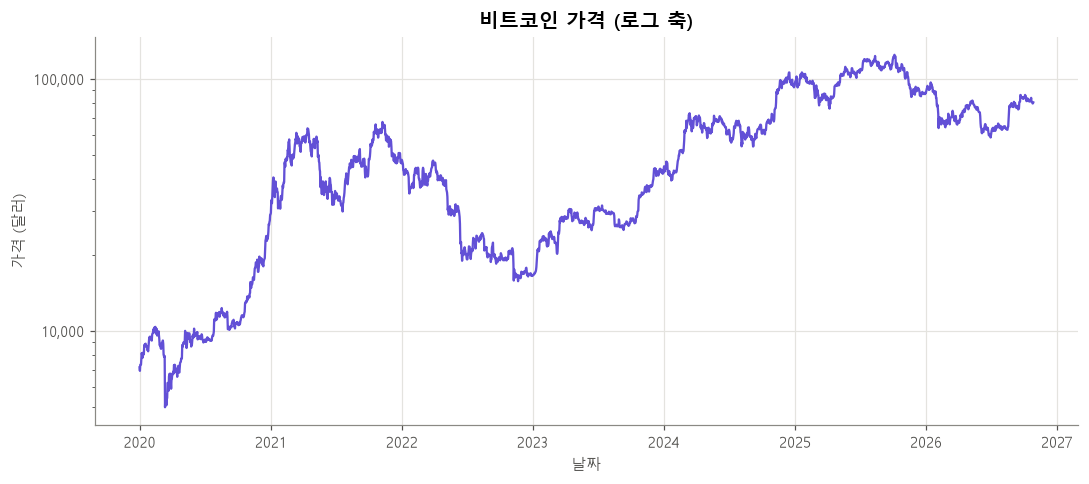

In [36]:
BTC_COLOR = "#6250d6"   # 보라 (비트코인 전용)

fig, ax = plt.subplots()
ax.plot(btc.index, btc.values, color=BTC_COLOR)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax.set_title("비트코인 가격 (로그 축)")
ax.set_xlabel("날짜")
ax.set_ylabel("가격 (달러)")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_btc_price.png", dpi=200)
plt.show()

## 2-8. 금리와 합치기

### 금리 데이터 불러오기
이 셀이 하는 일: 섹션 1에서 저장한 `rates.parquet`에서 **기준금리**(`base_rate`)와 **2년물 국채금리**(`DGS2`)를 가져온다.

왜 두 금리를 같이 보나?
- **기준금리**: **지금** 준비금이 받는 금리. 발행사 이익에 바로 들어간다.
- **2년물 국채금리**: 시장이 예상하는 **앞으로 2년간의 평균 단기금리**에 가깝다. 사람들은 금리가 실제로 바뀌기 **전에** 예상만으로 움직일 수 있다. 2년물이 기준금리보다 먼저 움직였다면, 유통량도 기대를 따라 먼저 움직였는지 비교해 볼 수 있다.
- 2년물 − 기준금리 > 0 이면 시장이 **인상**을, < 0 이면 **인하**를 예상한다는 뜻이다.

In [37]:
rates_saved = pd.read_parquet(PROC_DIR / "rates.parquet")
rates_saved[["base_rate", "base_source", "DGS2"]].tail(3)

,base_rate,base_source,DGS2
date,,,
2026-10-22,3.90,SOFR,4.65
2026-10-23,3.92,SOFR,4.69
2026-10-26,3.93,SOFR,4.68


### 날짜 기준으로 합치기
이 셀이 하는 일: USDC 날짜(매일)를 기준으로 모든 데이터를 붙여 `usdc_daily` 표를 만든다.
- 금리는 **주말·휴일에 공표되지 않는다.** 그날은 직전 영업일 금리가 그대로 적용되므로 **직전 값**으로 채운다. 기준금리의 출처 열에는 `주말(직전값)`이라고 적는다.
- 2020-01-01은 공휴일이라 그날 2년물 값이 없다. 그래서 **합치기 전에** 2000년부터 있는 금리 표에서 먼저 직전 값을 채운다(2019년 마지막 영업일 값).
- 비트코인 가격은 원본에서 **2020-09-04 하루**가 비어 있다. 월말이 아니라 월간 데이터에는 영향이 없고, 일별에서는 직전 값으로 채운다.
- **전체 시장**(`stable_total_bn`)은 2-4에서 정한 대로 **달러 스테이블코인 전체 − UST**다.

In [38]:
days = usdc.index   # 2020-01-01부터 매일

usdc_daily = pd.DataFrame({
    "usdc_bn":          usdc,
    "usdt_bn":          usdt.reindex(days),
    "stable_total_bn":  market_now,
    "btc_usd":          btc.reindex(days).ffill(),                        # 2020-09-04 하루 → 직전 값
    "base_rate":        rates_saved["base_rate"].reindex(days).ffill(),
    "base_source":      rates_saved["base_source"].reindex(days).fillna("주말(직전값)"),
    "dgs2":             rates_saved["DGS2"].ffill().reindex(days).ffill(),   # 휴일 먼저 채우고 → 주말 채우기
    "event_market":     event_cols["market"],
    "event_usdc":       event_cols["usdc"],
    "event_regulation": event_cols["regulation"],
    "event_name":       event_name,
    "data_flag":        data_flag,
    "data_note":        data_note,
})
usdc_daily.index.name = "date"

print("행, 열:", usdc_daily.shape)
print("빈 칸:", usdc_daily.drop(columns=["event_name"]).isna().sum().loc[lambda s: s > 0].to_dict() or "없음")

행, 열: (2491, 13)
빈 칸: 없음


## 2-9. USDC = 전체 시장 × USDC 점유율

USDC 유통량을 두 부분으로 나눈다.

$$\text{USDC} = \underbrace{\text{전체 스테이블코인 시장}}_{\text{시장이 커졌나?}} \times \underbrace{\text{USDC 점유율}}_{\text{USDC가 다른 코인보다 잘 팔렸나?}}$$

- 같은 "USDC 10% 증가"라도, 시장 전체가 커져서인지 USDC가 남의 몫을 가져와서인지에 따라 의미가 다르다.
- 금리는 모든 스테이블코인에 비슷하게 영향을 주므로 주로 **시장 크기** 쪽에, 바이낸스·SVB 같은 고유 사건은 주로 **점유율** 쪽에 나타날 것으로 예상할 수 있다.
- 양쪽에 **로그**를 씌우면 곱하기가 더하기로 바뀐다: log(USDC) = log(시장) + log(점유율). 그래서 다음 단계의 **월간 로그 변화율**도 "시장 변화율 + 점유율 변화율"로 정확히 나뉜다.
  - **로그 변화율**: log(이번 달) − log(지난달). 변화가 작을 때는 % 변화율과 거의 같다.

이 셀이 하는 일: 점유율 열(`usdc_share`, %)을 만들고, 시장 × 점유율이 USDC와 정확히 같은지 확인한다.

In [39]:
usdc_daily["usdc_share"] = usdc_daily["usdc_bn"] / usdc_daily["stable_total_bn"] * 100

rebuilt = usdc_daily["stable_total_bn"] * usdc_daily["usdc_share"] / 100   # 시장 × 점유율
print("시장 × 점유율 − USDC 의 최대 오차:", f"{(rebuilt - usdc_daily['usdc_bn']).abs().max():.2e}", "bn (0이면 정확)")

usdc_daily[["usdc_bn", "stable_total_bn", "usdc_share"]].iloc[[0, -1]].round(2)

시장 × 점유율 − USDC 의 최대 오차: 1.42e-14 bn (0이면 정확)


,usdc_bn,stable_total_bn,usdc_share
date,,,
2020-01-01,0.52,4.16,12.41
2026-10-26,71.71,302.82,23.68


## 2-10. 주간·월간 데이터 만들기
이 셀이 하는 일: 일별 표를 **주 단위**(일요일 마감)와 **월 단위**(말일 마감)로 묶는다.
- **유통량·시장·점유율·비트코인 가격은 그 기간의 마지막 날 값**을 쓴다. 유통량은 '잔액'이라 7일치를 더하면 의미가 없다. (은행 잔고를 일주일 치 더하지 않는 것과 같다) 월간 로그 변화율도 월말 값끼리 비교해야 한다.
- **금리는 그 기간의 평균**을 쓴다. 그 주(달) 동안 준비금이 평균적으로 받은 금리이기 때문이다.
- 이벤트·데이터 표시는 그 기간에 **하루라도** 있으면 1로 표시한다.

In [40]:
AGG_RULES = {
    "usdc_bn":          "last",   # 마지막 날 값
    "usdt_bn":          "last",
    "stable_total_bn":  "last",
    "usdc_share":       "last",
    "btc_usd":          "last",
    "base_rate":        "mean",   # 평균
    "dgs2":             "mean",
    "event_market":     "max",    # 하루라도 1이면 1
    "event_usdc":       "max",
    "event_regulation": "max",
    "data_flag":        "max",
}

usdc_weekly = usdc_daily.resample("W").agg(AGG_RULES)     # W: 주 단위 (일요일 마감)
usdc_monthly = usdc_daily.resample("ME").agg(AGG_RULES)   # ME: 월 단위 (말일 마감)

print("주간:", usdc_weekly.shape, "| 월간:", usdc_monthly.shape)
usdc_monthly.loc[usdc_monthly[["event_market", "event_usdc", "event_regulation"]].any(axis=1)]

주간: (357, 11) | 월간: (82, 11)


,usdc_bn,usdt_bn,stable_total_bn,usdc_share,btc_usd,base_rate,dgs2,event_market,event_usdc,event_regulation,data_flag
date,,,,,,,,,,,
2022-05-31,53.740917,72.563691,158.777842,33.846610,31804.27,0.721290,2.610323,1,0,0,False
2022-09-30,47.899407,67.951354,149.499370,32.039872,19415.80,2.489667,3.813667,0,1,0,False
2022-10-31,43.017550,69.258582,145.740844,29.516469,20472.79,3.034194,4.374194,0,1,0,False
2022-11-30,42.807756,65.282829,141.295586,30.296598,17179.78,3.745667,4.491000,1,0,0,False
2023-03-31,32.596519,79.665015,131.736579,24.743711,28492.72,4.629677,4.290968,0,1,0,False
2025-07-31,63.695607,164.580462,264.183852,24.110333,113248.73,4.335484,3.884839,0,0,1,False
2025-08-31,71.341964,168.005950,280.910657,25.396674,109240.55,4.346129,3.700645,0,0,1,False


## 2-11. 그래프

### 그래프 공통 준비
이 셀이 하는 일: 섹션 2 그래프에서 쓸 색을 정하고, 이벤트를 세로선으로 그리는 함수를 만든다.
- 이벤트 종류마다 선 모양을 다르게 한다: 시장 전체 충격 `--`(긴 점선), USDC 고유 충격 `:`(짧은 점선), 제도 변화 `-.`(점·선)
- 이벤트가 몰려 있어 이름이 겹치지 않도록 글씨를 **세로로**, 선의 **오른쪽·왼쪽 번갈아** 적는다. 글씨가 데이터를 가리지 않게 그래프 위쪽에 여백을 둔다.

In [41]:
COIN_COLORS = {"USDC": COLORS[0], "USDT": COLORS[1]}   # 섹션 2 전체에서 색은 고정
MARKET_COLOR = "#d55181"                                 # 전체 시장: 자주색
RATE_COLORS = {"base_rate": COLORS[2], "dgs2": COLORS[3]}
EVENT_STYLES = {"market": "--", "usdc": ":", "regulation": "-."}
EVENT_KIND_NAMES = {"market": "시장 전체 충격", "usdc": "USDC 고유 충격", "regulation": "제도 변화"}


def draw_events(ax, with_labels=True):
    # 이벤트 시작일에 세로선을 긋고, 원하면 이름을 세로로 적는다
    if with_labels:
        low, high = ax.get_ylim()
        ax.set_ylim(low, high + (high - low) * 0.45)   # 위쪽에 글씨 들어갈 여백
    by_date = sorted(EVENTS.items(), key=lambda item: item[1][1])   # 날짜순
    for i, (name, (kind, start, end)) in enumerate(by_date):
        ax.axvline(pd.Timestamp(start), color=MUTED, linestyle=EVENT_STYLES[kind], linewidth=1.2)
        if with_labels:
            ax.text(pd.Timestamp(start), ax.get_ylim()[1], f" {name} ", rotation=90,
                    ha="left" if i % 2 == 0 else "right",   # 선 오른쪽 / 왼쪽 번갈아
                    va="top", color=TEXT_SUB, fontsize=8)


def event_legend_handles():
    # 범례에 넣을 '이벤트 종류별 선 모양' 견본
    from matplotlib.lines import Line2D
    return [Line2D([], [], color=MUTED, linestyle=style, label=EVENT_KIND_NAMES[kind])
            for kind, style in EVENT_STYLES.items()]


def draw_rates(ax):
    # 아래 칸: 기준금리와 2년물 국채금리
    ax.plot(usdc_daily.index, usdc_daily["base_rate"], color=RATE_COLORS["base_rate"], label="기준금리")
    ax.plot(usdc_daily.index, usdc_daily["dgs2"], color=RATE_COLORS["dgs2"], label="2년물 국채금리")
    ax.set_ylabel("금리 (%)")
    ax.legend(loc="upper left")

### USDC와 USDT 유통량
이 셀이 하는 일: 두 코인의 유통량(bn 달러)을 한 그래프에 그린다. 단위가 같으므로 축 하나로 그린다.

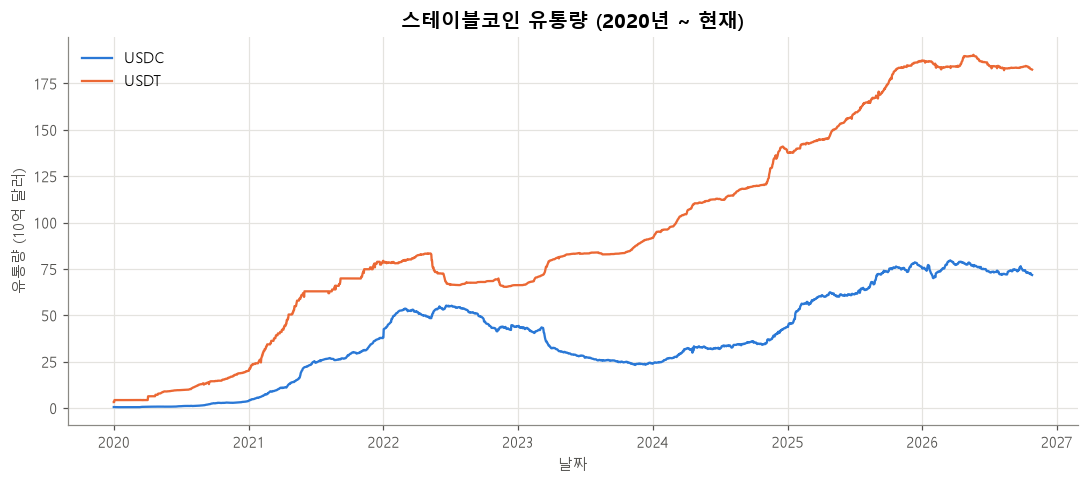

In [42]:
fig, ax = plt.subplots()
ax.plot(usdc_daily.index, usdc_daily["usdc_bn"], color=COIN_COLORS["USDC"], label="USDC")
ax.plot(usdc_daily.index, usdc_daily["usdt_bn"], color=COIN_COLORS["USDT"], label="USDT")

ax.set_title("스테이블코인 유통량 (2020년 ~ 현재)")
ax.set_xlabel("날짜")
ax.set_ylabel("유통량 (10억 달러)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_usdc_usdt_supply.png", dpi=200)
plt.show()

### 전체 스테이블코인 시장과 금리
이 셀이 하는 일: 위 칸에 **전체 시장**(UST 제외), 아래 칸에 **기준금리와 2년물**을 그린다. 가로축(날짜)은 공유한다.
- 금리와 시장은 단위가 달라서 축 하나에 못 그린다. 축 2개 대신 **위아래로 나눠** 그리면, 축 범위 때문에 생기는 착시 없이 **움직인 시점**을 비교할 수 있다.

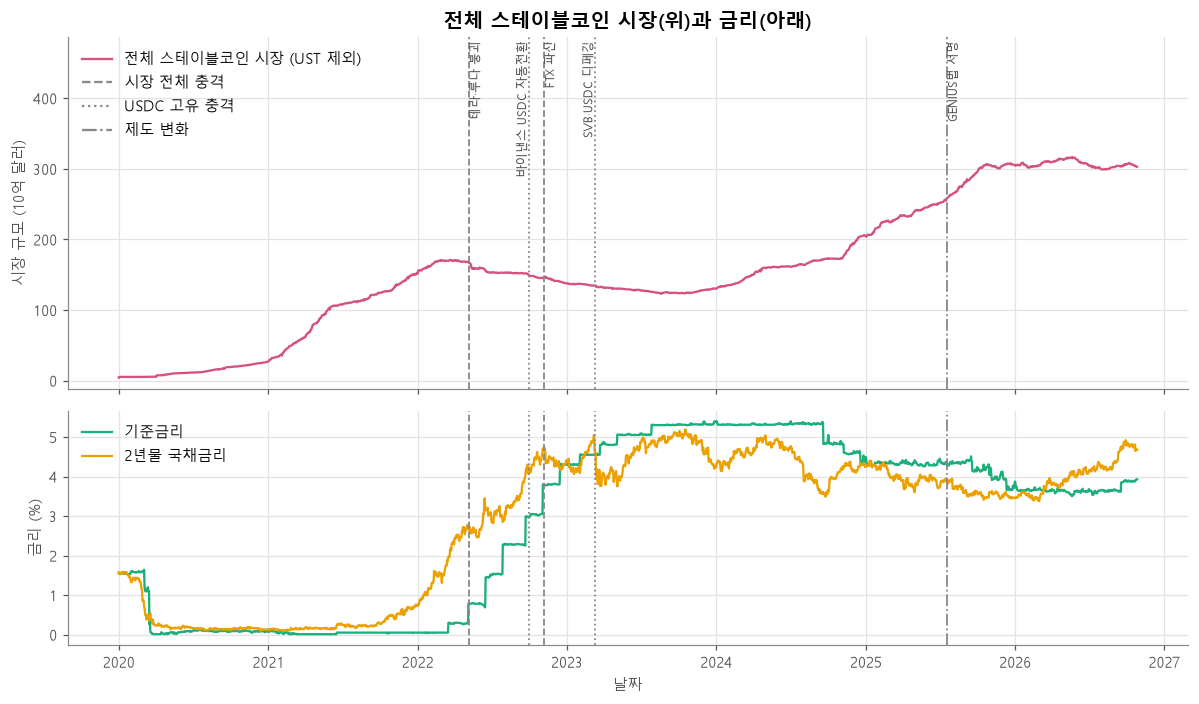

In [43]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})

top.plot(usdc_daily.index, usdc_daily["stable_total_bn"], color=MARKET_COLOR, label="전체 스테이블코인 시장 (UST 제외)")
top.set_ylabel("시장 규모 (10억 달러)")
top.legend(handles=top.get_legend_handles_labels()[0] + event_legend_handles(), loc="upper left")
draw_events(top)

draw_rates(bottom)
draw_events(bottom, with_labels=False)

top.set_title("전체 스테이블코인 시장(위)과 금리(아래)")
bottom.set_xlabel("날짜")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_market_and_rates.png", dpi=200)
plt.show()

### USDC 점유율과 금리
이 셀이 하는 일: 위 칸에 **USDC 점유율**(전체 시장 중 USDC 비중), 아래 칸에 금리를 그린다.
- 2020년 1·4월의 USDT 계단(2-5) 때문에 2020년 초반 점유율은 조심해서 봐야 한다.

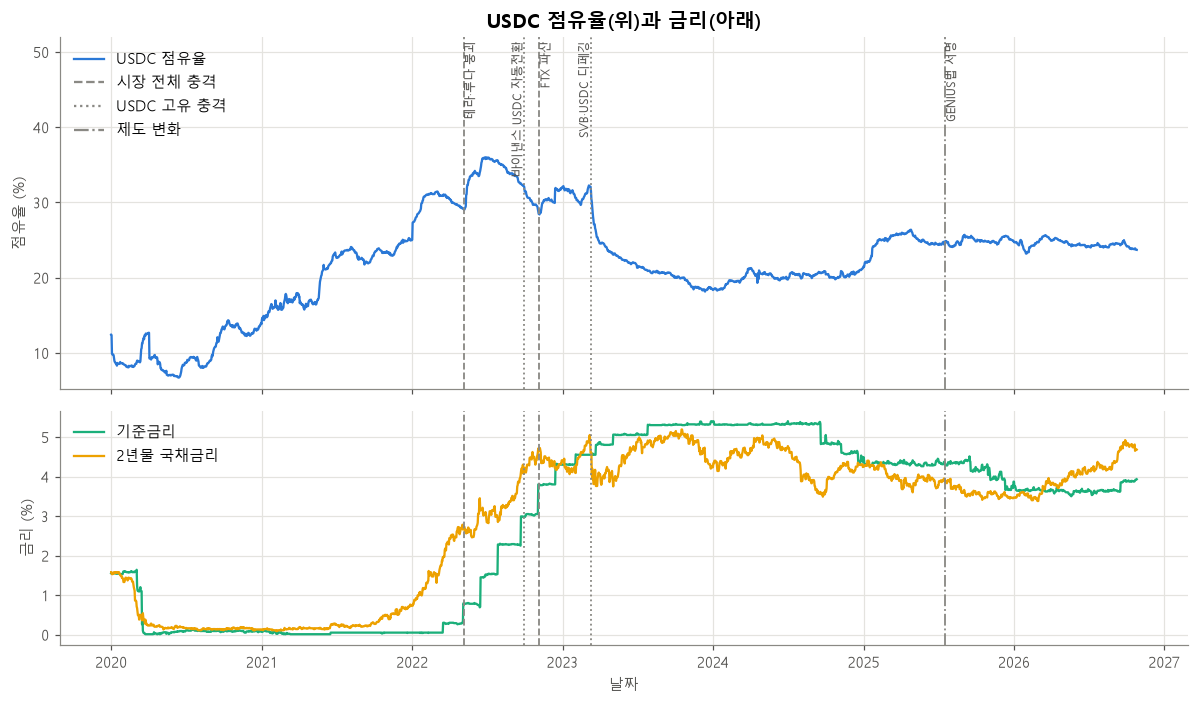

In [44]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 2]})

top.plot(usdc_daily.index, usdc_daily["usdc_share"], color=COIN_COLORS["USDC"], label="USDC 점유율")
top.set_ylabel("점유율 (%)")
top.legend(handles=top.get_legend_handles_labels()[0] + event_legend_handles(), loc="upper left")
draw_events(top)

draw_rates(bottom)
draw_events(bottom, with_labels=False)

top.set_title("USDC 점유율(위)과 금리(아래)")
bottom.set_xlabel("날짜")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_share_and_rates.png", dpi=200)
plt.show()

### USDC 유통량과 기준금리 (축 2개)
이 셀이 하는 일: 왼쪽 축에 USDC 유통량, 오른쪽 축에 기준금리를 그리고 이벤트를 세로선으로 표시한다.

> **축 2개 그래프를 볼 때 주의:** 두 선이 "같이 움직이는 것처럼" 보이는 정도는 **양쪽 축의 범위를 어떻게 잡느냐**에 따라 달라진다. 판단은 위의 위아래 그래프와 2-13의 표로 한다.

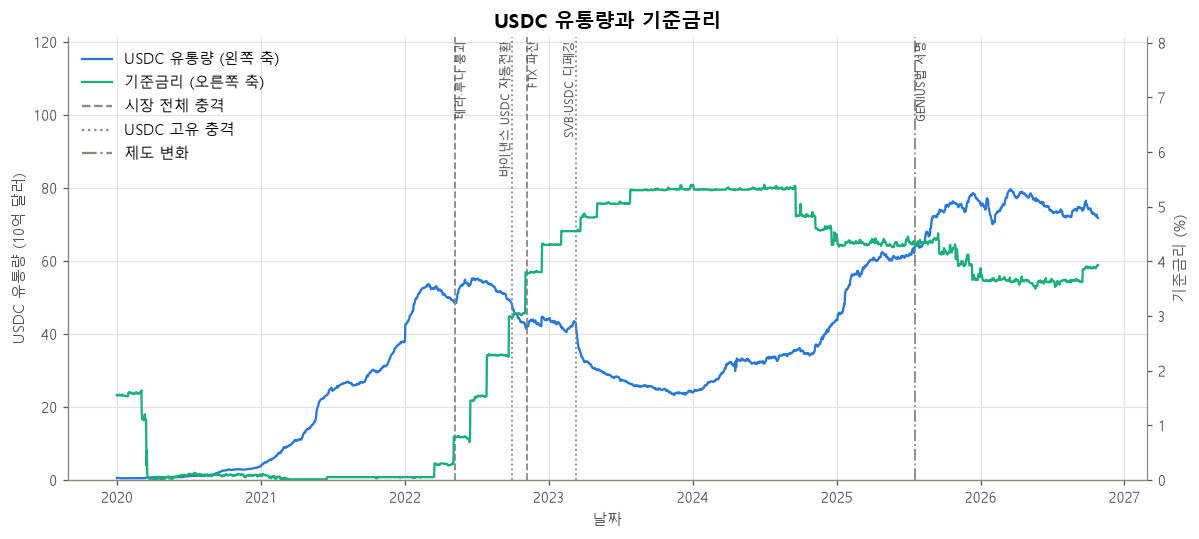

In [45]:
fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()   # 같은 가로축을 쓰는 두 번째 세로축(오른쪽)

line1, = ax1.plot(usdc_daily.index, usdc_daily["usdc_bn"], color=COIN_COLORS["USDC"], label="USDC 유통량 (왼쪽 축)")
line2, = ax2.plot(usdc_daily.index, usdc_daily["base_rate"], color=RATE_COLORS["base_rate"], label="기준금리 (오른쪽 축)")

ax1.set_ylim(0, usdc_daily["usdc_bn"].max() * 1.05)
ax2.set_ylim(0, usdc_daily["base_rate"].max() * 1.5)   # 왼쪽 축의 위쪽 여백(×1.45)과 높이를 비슷하게
draw_events(ax1)

ax2.spines["right"].set_visible(True)
ax2.grid(False)   # 격자는 왼쪽 축 것만

ax1.set_title("USDC 유통량과 기준금리")
ax1.set_xlabel("날짜")
ax1.set_ylabel("USDC 유통량 (10억 달러)")
ax2.set_ylabel("기준금리 (%)")
ax1.legend(handles=[line1, line2] + event_legend_handles(), loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "2_usdc_vs_base_rate.png", dpi=200)
plt.show()

## 2-12. 저장
이 셀이 하는 일: 일별·주간·월간 표를 parquet로 저장하고, 일별 파일을 다시 읽어 확인한다.

| 파일 | 내용 |
|---|---|
| `data/processed/usdc_rates.parquet` | 일별 (2020-01-01~) |
| `data/processed/usdc_rates_weekly.parquet` | 주간 (일요일 마감) |
| `data/processed/usdc_rates_monthly.parquet` | 월간 (말일 마감) ← 다음 단계 회귀용 |

| 열 | 내용 |
|---|---|
| `usdc_bn`, `usdt_bn` | 유통량 (10억 달러, 코인 개수 기준) |
| `stable_total_bn` | 전체 달러 스테이블코인 시장 (UST 제외) |
| `usdc_share` | USDC 점유율 = USDC ÷ 전체 시장 × 100 (%) |
| `btc_usd` | 비트코인 가격 (달러, 통제 변수) |
| `base_rate`, `base_source` | 기준금리와 출처 (주말은 `주말(직전값)`) |
| `dgs2` | 2년물 국채금리 (%, 금리 기대 지표) |
| `event_market`, `event_usdc`, `event_regulation` | 이벤트 종류별 0/1 |
| `event_name` | 이벤트 이름 (일별만) |
| `data_flag`, `data_note` | 데이터 오류 의심 여부와 이유 (`data_note`는 일별만) |

In [46]:
usdc_daily.to_parquet(PROC_DIR / "usdc_rates.parquet")
usdc_weekly.to_parquet(PROC_DIR / "usdc_rates_weekly.parquet")
usdc_monthly.to_parquet(PROC_DIR / "usdc_rates_monthly.parquet")

check = pd.read_parquet(PROC_DIR / "usdc_rates.parquet")
print("저장 완료 | 일별:", check.shape, "| 기간:", check.index[0].date(), "~", check.index[-1].date())
check.dtypes

저장 완료 | 일별: (2491, 14) | 기간: 2020-01-01 ~ 2026-10-26


usdc_bn             float64
usdt_bn             float64
stable_total_bn     float64
btc_usd             float64
base_rate           float64
base_source             str
dgs2                float64
event_market          int64
event_usdc            int64
event_regulation      int64
event_name           string
data_flag              bool
data_note               str
usdc_share          float64
dtype: object

## 2-13. 국면별 정리 (회귀분석 전, 숫자로 확인)
이 셀이 하는 일: 금리 국면별로 USDC, 전체 시장, 점유율, 비트코인, 2년물이 어떻게 변했는지 표로 정리한다.

In [47]:
PHASES = {
    "제로금리":          ("2020-03-16", "2022-03-16"),
    "인상기":            ("2022-03-17", "2023-07-27"),
    "고금리 유지":        ("2023-07-28", "2024-09-17"),
    "인하기":            ("2024-09-18", "2025-12-10"),
    "인하 멈춤~재인상":    ("2025-12-11", str(usdc_daily.index[-1].date())),
}

phase_rows = {}
for name, (start, end) in PHASES.items():
    p = usdc_daily.loc[start:end]
    first, last = p.iloc[0], p.iloc[-1]
    phase_rows[name] = {
        "평균 기준금리(%)":   round(p["base_rate"].mean(), 2),
        "2년물 시작→끝(%)":   f"{first['dgs2']:.2f} → {last['dgs2']:.2f}",
        "USDC(bn)":         f"{first['usdc_bn']:.1f} → {last['usdc_bn']:.1f}",
        "전체 시장(bn)":      f"{first['stable_total_bn']:.0f} → {last['stable_total_bn']:.0f}",
        "USDC 점유율(%)":    f"{first['usdc_share']:.1f} → {last['usdc_share']:.1f}",
        "비트코인(천 달러)":   f"{first['btc_usd'] / 1000:.0f} → {last['btc_usd'] / 1000:.0f}",
    }
pd.DataFrame(phase_rows).T

,평균 기준금리(%),2년물 시작→끝(%),USDC(bn),전체 시장(bn),USDC 점유율(%),비트코인(천 달러)
제로금리,0.05,0.36 → 1.95,0.6 → 52.3,5 → 170,11.2 → 30.9,5 → 41
인상기,3.19,1.94 → 4.91,52.3 → 26.2,170 → 126,30.9 → 20.9,41 → 29
고금리 유지,5.32,4.87 → 3.59,26.3 → 35.2,126 → 171,20.9 → 20.6,29 → 62
인하기,4.37,3.61 → 3.54,35.4 → 78.1,172 → 306,20.6 → 25.5,63 → 91
인하 멈춤~재인상,3.67,3.52 → 4.68,78.2 → 71.7,306 → 303,25.5 → 23.7,92 → 80


### 정리 (2026-10-26 데이터 기준, 회귀분석 전)

**분해해서 보니 달라 보이는 것**
- **전체 시장**은 금리 국면과 큰 흐름이 맞는다. 첫 인상(2022-03-17) 직후인 2022-03-21에 정점(170bn)을 찍고 줄었다. 바닥은 2023-08-19(123bn)로, 2년물 금리 정점(2023-10-17, 5.19%)보다 두 달 빨랐다. 실제 첫 인하(2024-09)보다는 1년 넘게 앞선다. → 기준금리보다 **금리 기대(2년물)** 쪽이 시점이 더 가깝다.
- 하지만 **고금리 유지기**(평균 5.3%)에도 시장은 126 → 171bn으로 커졌다. 같은 기간 비트코인은 2배 넘게 올랐다. → 금리만으로는 설명이 안 되고, **코인 시장 분위기**가 큰 몫을 한다.
- **USDC 점유율**은 금리보다 **USDC 고유 사건**에서 크게 움직인다. 바이낸스 자동전환과 SVB 이후 32% → 21%로 떨어졌다. 그 뒤 고금리 유지기 내내 21% 근처에 머물렀고, 2025년 초에 21% → 26%로 올랐다.
- 이벤트 분류도 데이터와 맞는다. SVB 기간에는 USDC −10.6bn, USDT +7.9bn으로 **고유 충격**이고, 테라 기간에는 전체 시장 −8.2bn으로 **시장 충격**이다(2-6 표).

**다음 단계(월간 로그 변화율 회귀) 전에 정해야 할 것**
1. **마지막 달(2026-10)은 26일까지만 있다.** 월간 표의 10월 값은 '월말'이 아니므로 회귀에서는 빼야 한다.
2. **전체 시장 안에 USDC가 들어 있다**(약 24%). 그래서 USDC와 시장은 기계적으로 같이 움직인다. 시장을 설명변수로 쓸 때는 **USDC를 뺀 시장**(`stable_total_bn − usdc_bn`)도 검토하자.
3. **2020년 1월·4월의 USDT 계단**은 그 달의 시장·점유율 변화율에 그대로 들어간다. 더미로 처리하거나, 시작 시점을 2020년 5월로 늦추는 방법이 있다.
4. **금리를 '수준'으로 넣을지 '변화'로 넣을지** 정해야 한다. 기회비용 논리라면 금리 수준이 유통량 **증가율**에 영향을 준다. 기대 효과는 2년물 변화로 볼 수 있다.
5. **관측치가 적다.** 월간 약 80개다. 금리 2개, 비트코인, 이벤트 3개를 넣으면 추정할 계수가 많아지므로, 변수 수를 아껴야 한다.
6. 바이낸스 자동전환처럼 **이벤트가 두 달에 걸치면** 월간 더미가 두 달 모두 1이 된다(2022년 9·10월).

# 3. Circle 재무제표

**목표:** 발행사 손익 π = (1 − s)·r·R − C 에 들어갈 **고정비 C**와 **배분율 s**를 USDC 발행사 Circle의 실제 공시로 추정한다.

| 기호 | 뜻 | Circle 공시에서 |
|---|---|---|
| C | 연간 고정비 | 영업비용 (인건비, 일반관리비, IT, 감가상각 등) |
| s | 배분율: 준비금 이자 중 유통 파트너(Coinbase 등)에게 주는 몫 | 유통·거래 비용 ÷ 준비금 이자수익 |

## 3-1. SEC EDGAR XBRL API

**SEC EDGAR**: 미국 상장회사의 공시를 모아 둔 미국 증권거래위원회(SEC)의 시스템. **XBRL**은 재무제표 숫자에 "이건 매출, 이건 영업비용" 같은 **표준 이름표(태그)**를 붙여 둔 형식이라, 프로그램으로 숫자를 바로 뽑을 수 있다.

| 주소 | 돌려주는 것 |
|---|---|
| `https://data.sec.gov/api/xbrl/companyfacts/CIK0001876042.json` | Circle(CIK 1876042)의 모든 XBRL 숫자 (표준 태그) |

- **CIK**: SEC가 회사마다 붙인 고유번호.
- SEC는 요청할 때 **User-Agent**(누가 요청하는지: 이름 + 이메일)를 꼭 적으라고 요구한다. 없으면 접속이 거부된다.

### 다운로드
이 셀이 하는 일: Circle의 XBRL 데이터를 받아 `data/raw/sec/circle_companyfacts.json`에 그대로 저장한다.

In [48]:
SEC_DIR = PROJECT / "data" / "raw" / "sec"
SEC_DIR.mkdir(parents=True, exist_ok=True)
SEC_USER_AGENT = "stablecoin-floor research drake1118@hanyang.ac.kr"   # SEC 요구: 이름 + 이메일
CIRCLE_CIK = "0001876042"

sec_path = SEC_DIR / "circle_companyfacts.json"
REFRESH_SEC = False
if REFRESH_SEC or not sec_path.exists():
    response = requests.get(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{CIRCLE_CIK}.json",
                            headers={"User-Agent": SEC_USER_AGENT}, timeout=60)
    response.raise_for_status()
    sec_path.write_bytes(response.content)
    print("저장 완료 →", sec_path.name)
else:
    print("이미 받은 파일이 있어 건너뜀")

facts = json.loads(sec_path.read_text())
print("회사:", facts["entityName"], "| 표준 태그 수:", len(facts["facts"]["us-gaap"]))

이미 받은 파일이 있어 건너뜀
회사: CIRCLE INTERNET GROUP, INC. | 표준 태그 수: 292


## 3-2. 쓰는 태그

| 태그 | 뜻 |
|---|---|
| `Revenues` | 총수익 (준비금 이자 + 기타 수익) |
| `InterestAndDividendIncomeOperating` | **준비금 이자수익** |
| `OperatingExpenses` | **영업비용** 합계 |
| `OperatingIncomeLoss` | 영업이익 |
| `ShareBasedCompensation` | 주식보상비용 (영업비용에 포함, 현금이 나가지 않는 비용) |

**유통·거래 비용은 어떻게 구하나?** Circle은 이 항목을 자기 회사 전용 태그로 공시해서, 이 API(표준 태그만 제공)에는 없다. 대신 손익계산서의 관계를 이용한다.

$$\text{총수익} - \text{유통·거래 비용} - \text{영업비용} = \text{영업이익} \;\Rightarrow\; \text{유통·거래 비용} = \text{총수익} - \text{영업비용} - \text{영업이익}$$

### 분기 값 뽑기
이 셀이 하는 일: 각 태그에서 **3개월짜리(분기)** 값을 뽑는 함수를 만든다.
- XBRL에는 같은 숫자가 3개월·6개월·9개월·1년 등 여러 기간으로 들어 있다. 4분기는 따로 공시하지 않으므로 **1년 값 − 9개월 값**으로 계산한다.

In [49]:
def quarterly_values(tag):
    rows = pd.DataFrame(facts["facts"]["us-gaap"][tag]["units"]["USD"])
    rows = rows[rows["start"].notna()].copy()                       # 기간 값(손익 항목)만
    rows["start"] = pd.to_datetime(rows["start"])
    rows["end"] = pd.to_datetime(rows["end"])
    rows["days"] = (rows["end"] - rows["start"]).dt.days
    rows = rows.sort_values("filed").drop_duplicates(["start", "end"], keep="last")   # 정정 공시는 최신 값

    quarters = rows[rows["days"].between(80, 100)].set_index("end")["val"]
    annual = rows[rows["days"].between(350, 380)]
    nine = rows[rows["days"].between(260, 280)]
    for _, year in annual.iterrows():                               # 4분기 = 1년 − 9개월
        if year["end"] in quarters.index:
            continue
        first9 = nine[(nine["start"] == year["start"]) & (nine["end"] < year["end"])]
        if len(first9):
            quarters.loc[year["end"]] = year["val"] - first9["val"].iloc[-1]
    return quarters.sort_index() / 1e6                              # 백만 달러

### 분기 손익표
이 셀이 하는 일: 태그별 분기 값을 한 표로 모으고, 유통·거래 비용과 분기별 배분율 s를 계산한다.

In [50]:
circle_q = pd.DataFrame({
    "총수익":        quarterly_values("Revenues"),
    "준비금 이자":    quarterly_values("InterestAndDividendIncomeOperating"),
    "영업비용":       quarterly_values("OperatingExpenses"),
    "영업이익":       quarterly_values("OperatingIncomeLoss"),
    "주식보상비용":    quarterly_values("ShareBasedCompensation"),
}).dropna()
circle_q["유통·거래 비용"] = circle_q["총수익"] - circle_q["영업비용"] - circle_q["영업이익"]
circle_q["배분율 s"] = circle_q["유통·거래 비용"] / circle_q["준비금 이자"]
circle_q.index.name = "분기 말"
circle_q.round(2)

,총수익,준비금 이자,영업비용,영업이익,주식보상비용,유통·거래 비용,배분율 s
분기 말,,,,,,,
2024-06-30,430.03,423.26,131.41,50.25,16.70,248.38,0.59
2024-09-30,445.76,445.22,124.26,63.80,12.80,257.70,0.58
2024-12-31,435.37,432.97,130.03,0.79,11.14,304.55,0.70
2025-03-31,578.57,557.91,137.99,92.94,12.72,347.65,0.62
2025-06-30,658.08,634.27,576.72,-325.58,435.00,406.94,0.64
2025-09-30,739.76,711.24,211.13,81.02,59.10,447.61,0.63
2025-12-31,770.23,733.40,253.60,55.19,59.41,461.45,0.63
2026-03-31,694.13,652.51,242.35,45.00,51.84,406.78,0.62
2026-06-30,701.32,667.73,254.49,34.36,53.60,412.47,0.62


**읽는 법**
- **배분율 s**는 대부분 분기에서 약 0.58~0.64로 꽤 안정적이다(2024년 4분기만 0.70). 준비금 이자의 약 60%를 Coinbase 등 유통 파트너에게 넘긴다는 뜻이다.
- **영업비용**은 2025년 2분기에 크게 튄다. 6월 상장(IPO) 때 한꺼번에 잡힌 **주식보상비용**(약 4.4억 달러) 때문이다. 일회성이라 C 추정에서는 빼야 한다.
- 분기 값은 2024년 2분기부터 있다(상장 서류에 그 이전은 연간 값만 있다).

## 3-3. C와 s 추정

**결정 방법**: 상장 이후의 **최근 4개 분기**(TTM: 직전 12개월) 합계를 쓴다. IPO 일회성 비용이 빠지고, 지금의 비용 구조를 가장 잘 보여준다.
- C = 최근 4개 분기 영업비용 합계 (주식보상비용 포함)
- s = 최근 4개 분기 유통·거래 비용 합계 ÷ 준비금 이자 합계

이 셀이 하는 일: C와 s를 계산하고, 참고로 주식보상비용을 뺀 C도 보여준다.

In [51]:
ttm = circle_q.iloc[-4:]
C_circle = ttm["영업비용"].sum()                                   # 백만 달러 / 년
s_circle = ttm["유통·거래 비용"].sum() / ttm["준비금 이자"].sum()

print(f"기간: {ttm.index[0]:%Y-%m} ~ {ttm.index[-1]:%Y-%m} (최근 4개 분기)")
print(f"고정비 C  = {C_circle:,.0f} 백만 달러/년  (참고: 주식보상비용 제외 시 {C_circle - ttm['주식보상비용'].sum():,.0f})")
print(f"배분율 s  = {s_circle:.3f}  → 발행사 몫 1 − s = {1 - s_circle:.3f}")

기간: 2025-09 ~ 2026-06 (최근 4개 분기)
고정비 C  = 962 백만 달러/년  (참고: 주식보상비용 제외 시 738)
배분율 s  = 0.625  → 발행사 몫 1 − s = 0.375


### 점검: 준비금 이자 ÷ USDC 유통량 ≈ 금리?
이 셀이 하는 일: 분기 준비금 이자를 그 분기 평균 USDC 유통량으로 나눠 **연 수익률**로 바꾸고, 같은 분기 평균 SOFR와 비교한다. 비슷하면 "준비금 ≈ USDC 유통량, 수익률 ≈ 단기금리"라는 모형 가정이 맞는 것이다.

In [52]:
quarter_avg = usdc_daily[["usdc_bn", "base_rate"]].resample("QE").mean()
check_yield = pd.DataFrame({
    "평균 USDC(bn)":      quarter_avg["usdc_bn"],
    "준비금 수익률(%, 연)": circle_q["준비금 이자"] * 4 / (quarter_avg["usdc_bn"] * 1000) * 100,
    "평균 기준금리(%)":    quarter_avg["base_rate"],
}).dropna()
check_yield["차이(%p)"] = check_yield["준비금 수익률(%, 연)"] - check_yield["평균 기준금리(%)"]
check_yield.round(2)

,평균 USDC(bn),"준비금 수익률(%, 연)",평균 기준금리(%),차이(%p)
2024-06-30,32.28,5.24,5.32,-0.07
2024-09-30,34.15,5.21,5.27,-0.06
2024-12-31,37.95,4.56,4.67,-0.10
2025-03-31,54.05,4.13,4.33,-0.20
2025-06-30,60.91,4.17,4.32,-0.16
2025-09-30,67.49,4.22,4.33,-0.11
2025-12-31,75.89,3.87,3.99,-0.13
2026-03-31,75.28,3.47,3.66,-0.19
2026-06-30,76.73,3.48,3.62,-0.14


**읽는 법**: 9개 분기 모두 준비금 수익률이 기준금리보다 **0.1~0.2%p 낮을 뿐** 거의 같이 움직인다. "준비금 ≈ USDC 유통량, 준비금 수익률 ≈ 단기금리"라는 모형 가정이 데이터와 맞는다.

### 저장
이 셀이 하는 일: 분기 손익표와 C·s 추정값을 `data/processed/`에 저장한다.

In [53]:
circle_q.to_csv(PROC_DIR / "circle_quarterly.csv")
pd.Series({"C_musd_per_year": C_circle, "s": s_circle,
           "ttm_start": ttm.index[0].date(), "ttm_end": ttm.index[-1].date()}).to_csv(PROC_DIR / "circle_params.csv",
                                                                                    header=["value"])
print("저장 완료: circle_quarterly.csv, circle_params.csv")

저장 완료: circle_quarterly.csv, circle_params.csv


## 3-4. 정리
- **C ≈ 9.6억 달러/년**, **s ≈ 0.62** (2025-Q3 ~ 2026-Q2, 상장 이후 4개 분기).
- Circle 자신의 손익분기 금리: r* = C ÷ ((1 − s) × R). USDC 약 740억 달러 기준이면 약 3.5%로, 지금 SOFR(3.93%)와 멀지 않다.
- 준비금 수익률은 기준금리보다 매 분기 약 0.1~0.2%p 낮다. 모형은 준비금 수익률 = 기준금리로 두므로 이 차이만큼 이익을 조금 크게 본다(한계).
- 한계: 유통·거래 비용을 손익 관계로 역산했다(기타 비용이 조금 섞임). 기타 수익(총수익 − 준비금 이자, 분기 약 3~4천만 달러)은 모형에서 뺐다.